# compute inundation ratio changes


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import jenkspy
import os, sys

In [6]:
energy_type = 'PVC_All_256Sites_GeomFixed'

In [36]:
def change_plot(csv):
    odir = os.path.dirname(csv)
    fn = os.path.basename(csv).split('.')[0]
    df = pd.read_csv(csv)
    rps = [2, 5, 10, 25, 50, 100, 200]
    col_rps = [ f'RP{rp}' for rp in rps ]
    col_changes = [ f'{rps[i]}TO{rps[i+1]}' for i in range(len(rps) - 1) ]
    df_changes = df[col_rps].diff(axis=1)
    df_changes.drop(columns=[col_rps[0]], inplace=True)
    df_changes['ClusterLab'] = df['ClusterLab']
    df_changes.rename(columns={col_rps[i+1]: col_changes[i] for i in range(len(rps) - 1)}, inplace=True)
    df_changes = df_changes[['ClusterLab'] + col_changes]
    df_changes.to_csv(f'{odir}/{fn}_changes.csv', index=False)

    # plot changes with natural breaks: 2 classes, save plot png
    for num_classes in [2, 4]: 
        fig, axs = plt.subplots(len(col_changes) // 2, 2, figsize=(20, 6 * len(col_changes) / 2))
        for i, col in enumerate(col_changes):
            data = df_changes[col] * 100
            breaks = jenkspy.jenks_breaks(data, num_classes)
            axs[i//2, i%2].hist(data, bins=breaks)
            axs[i//2, i%2].set_title(col)
            axs[i//2, i%2].set_xticks(breaks)
            axs[i//2, i%2].set_xlabel('Change in Inundation Ratio Percentage')
            axs[i//2, i%2].set_ylabel('Count')
        fig.savefig(f'{odir}/{fn}_changes_jenks_{num_classes}.png')

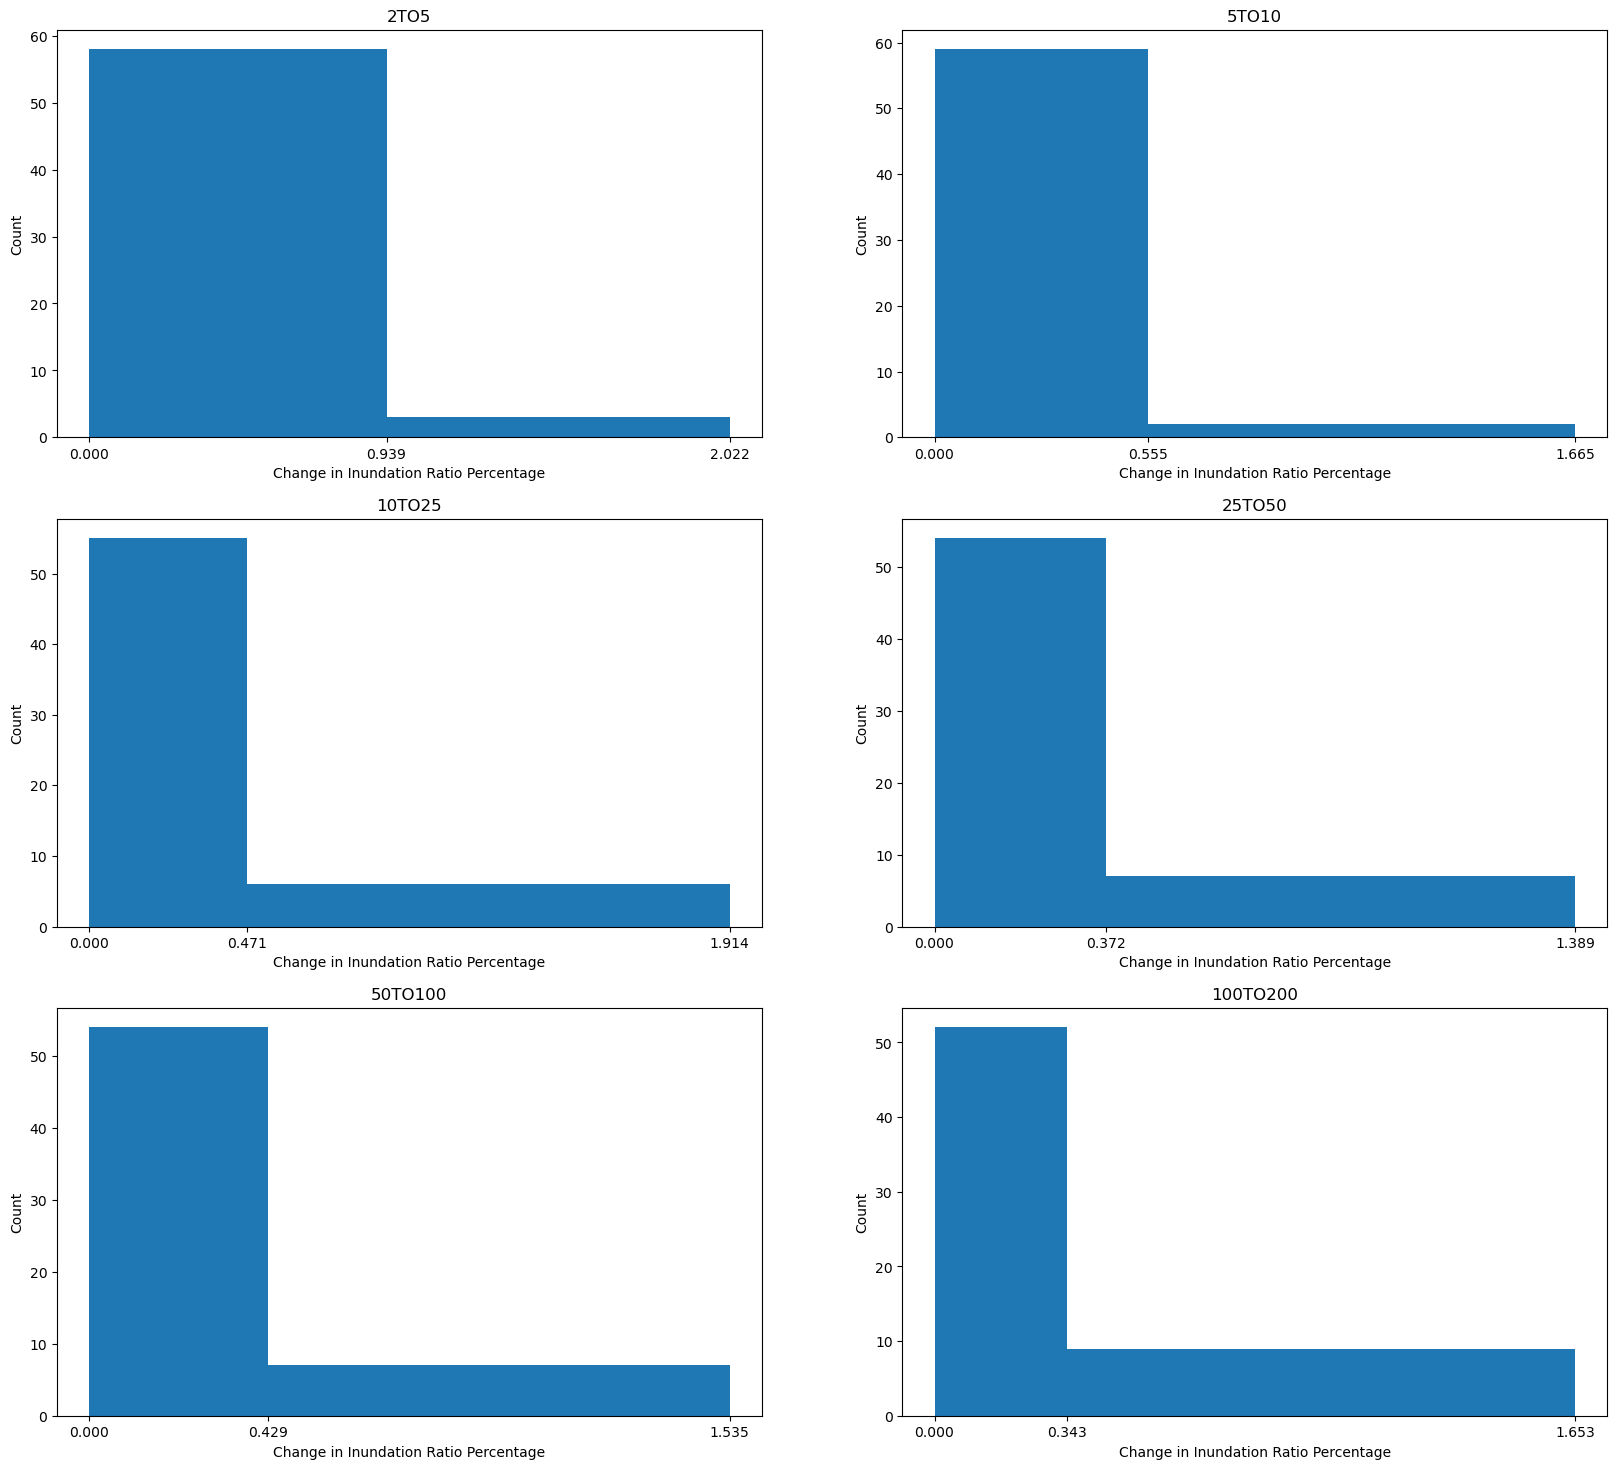

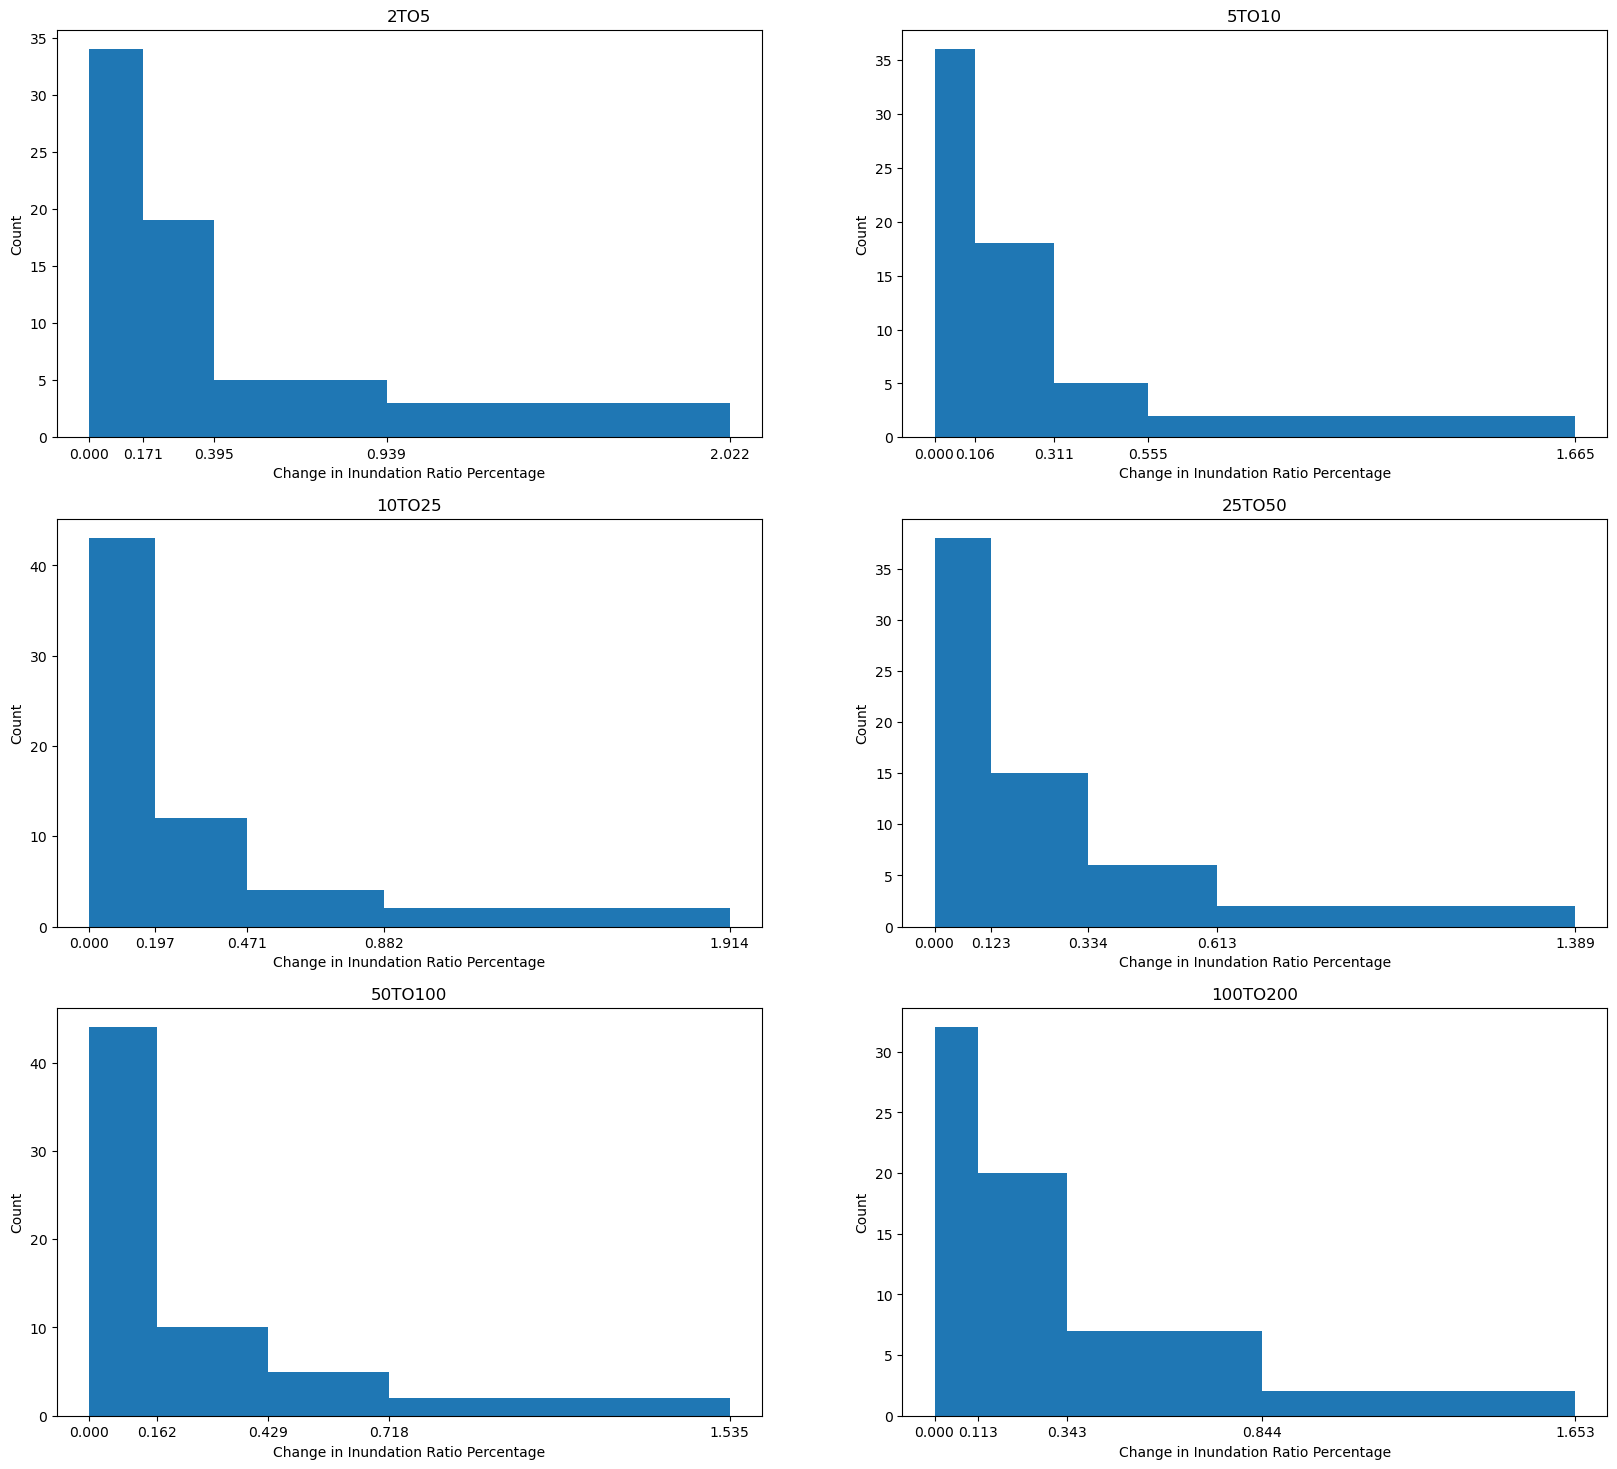

In [37]:
change_plot('/mnt/CADES_CEPH/netzero/inunmap/outputs/stats/site_inun_ratio_PV_14GW_Sites_GeomFixed_epsg5070.csv')

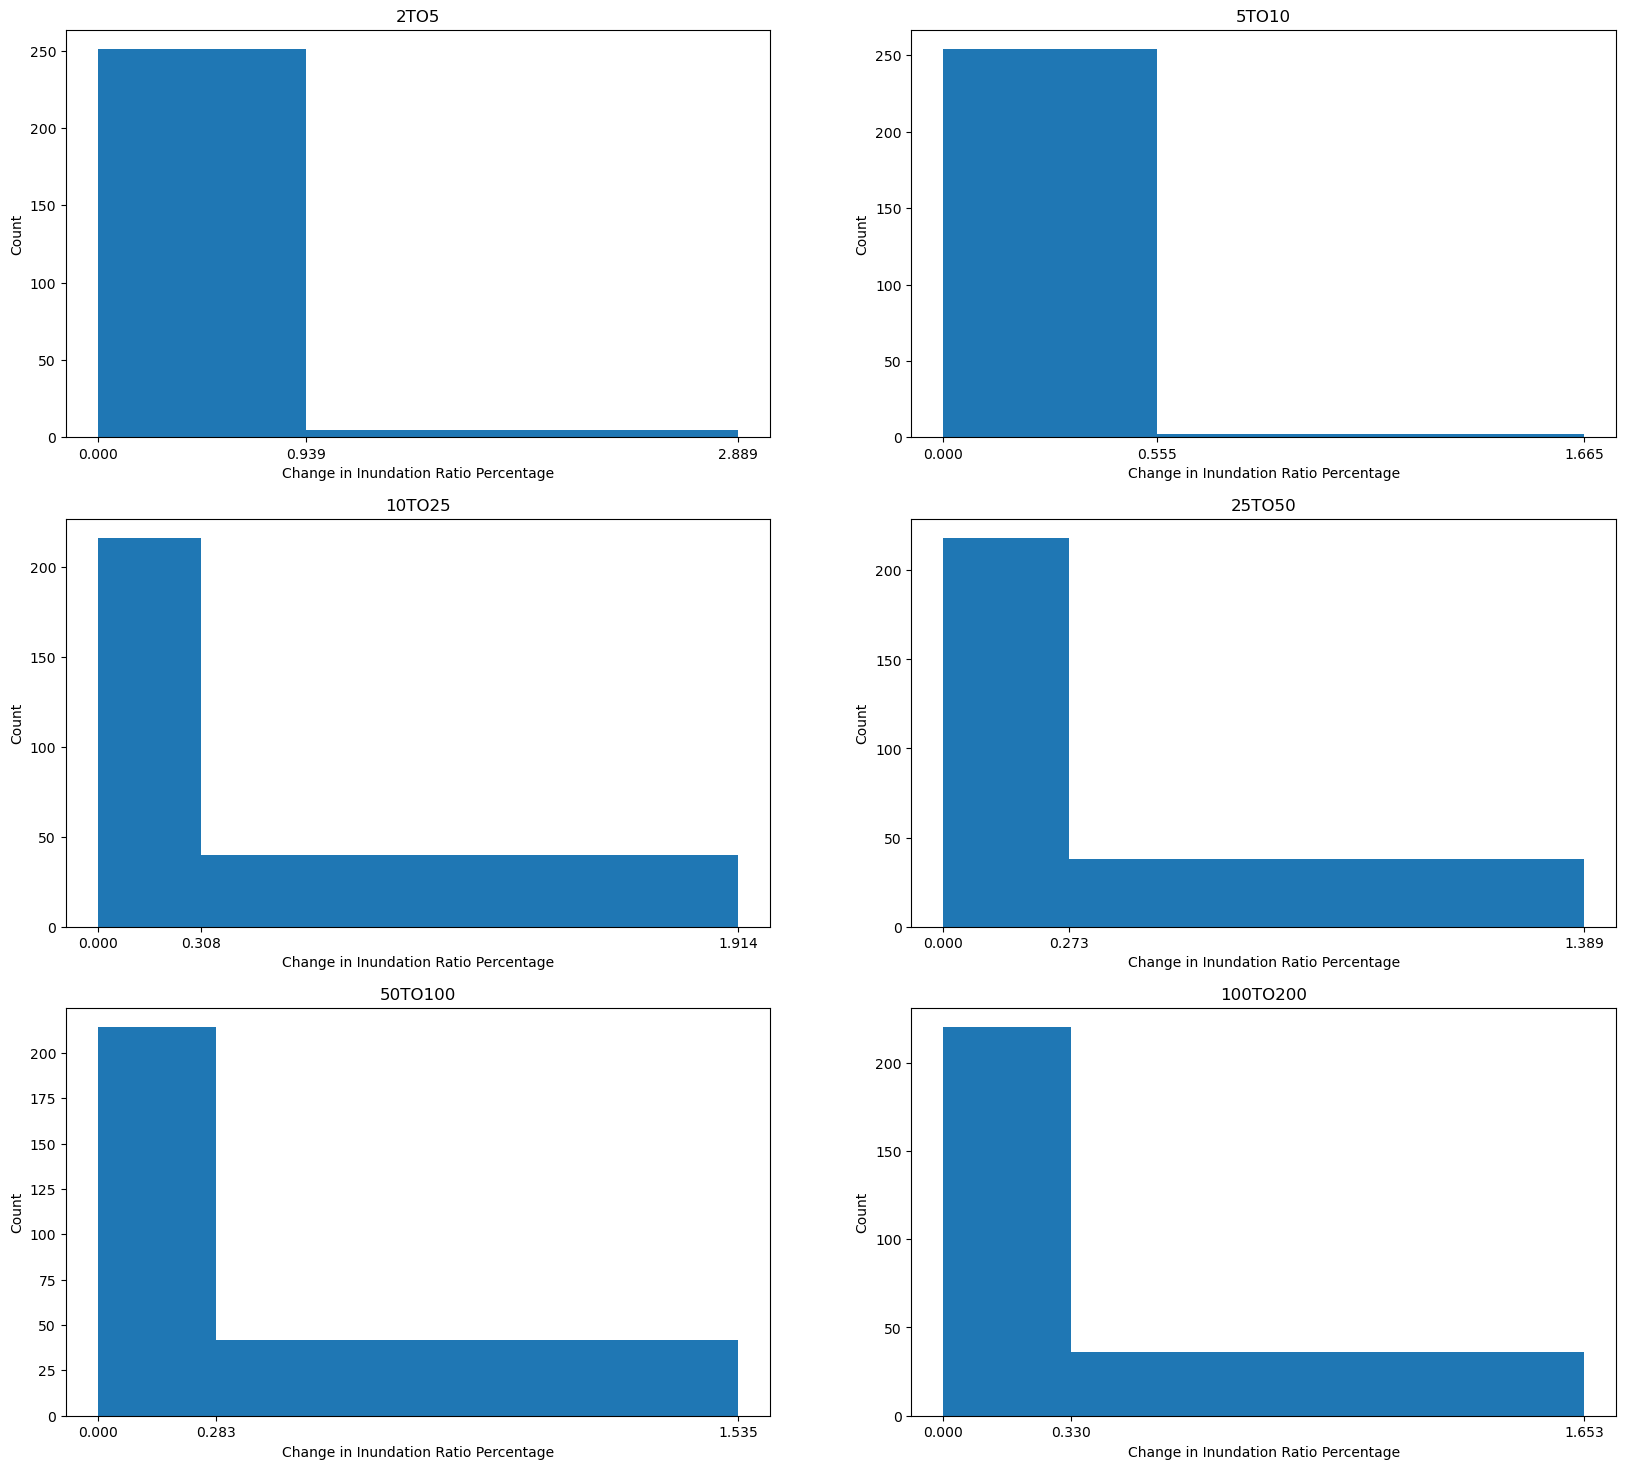

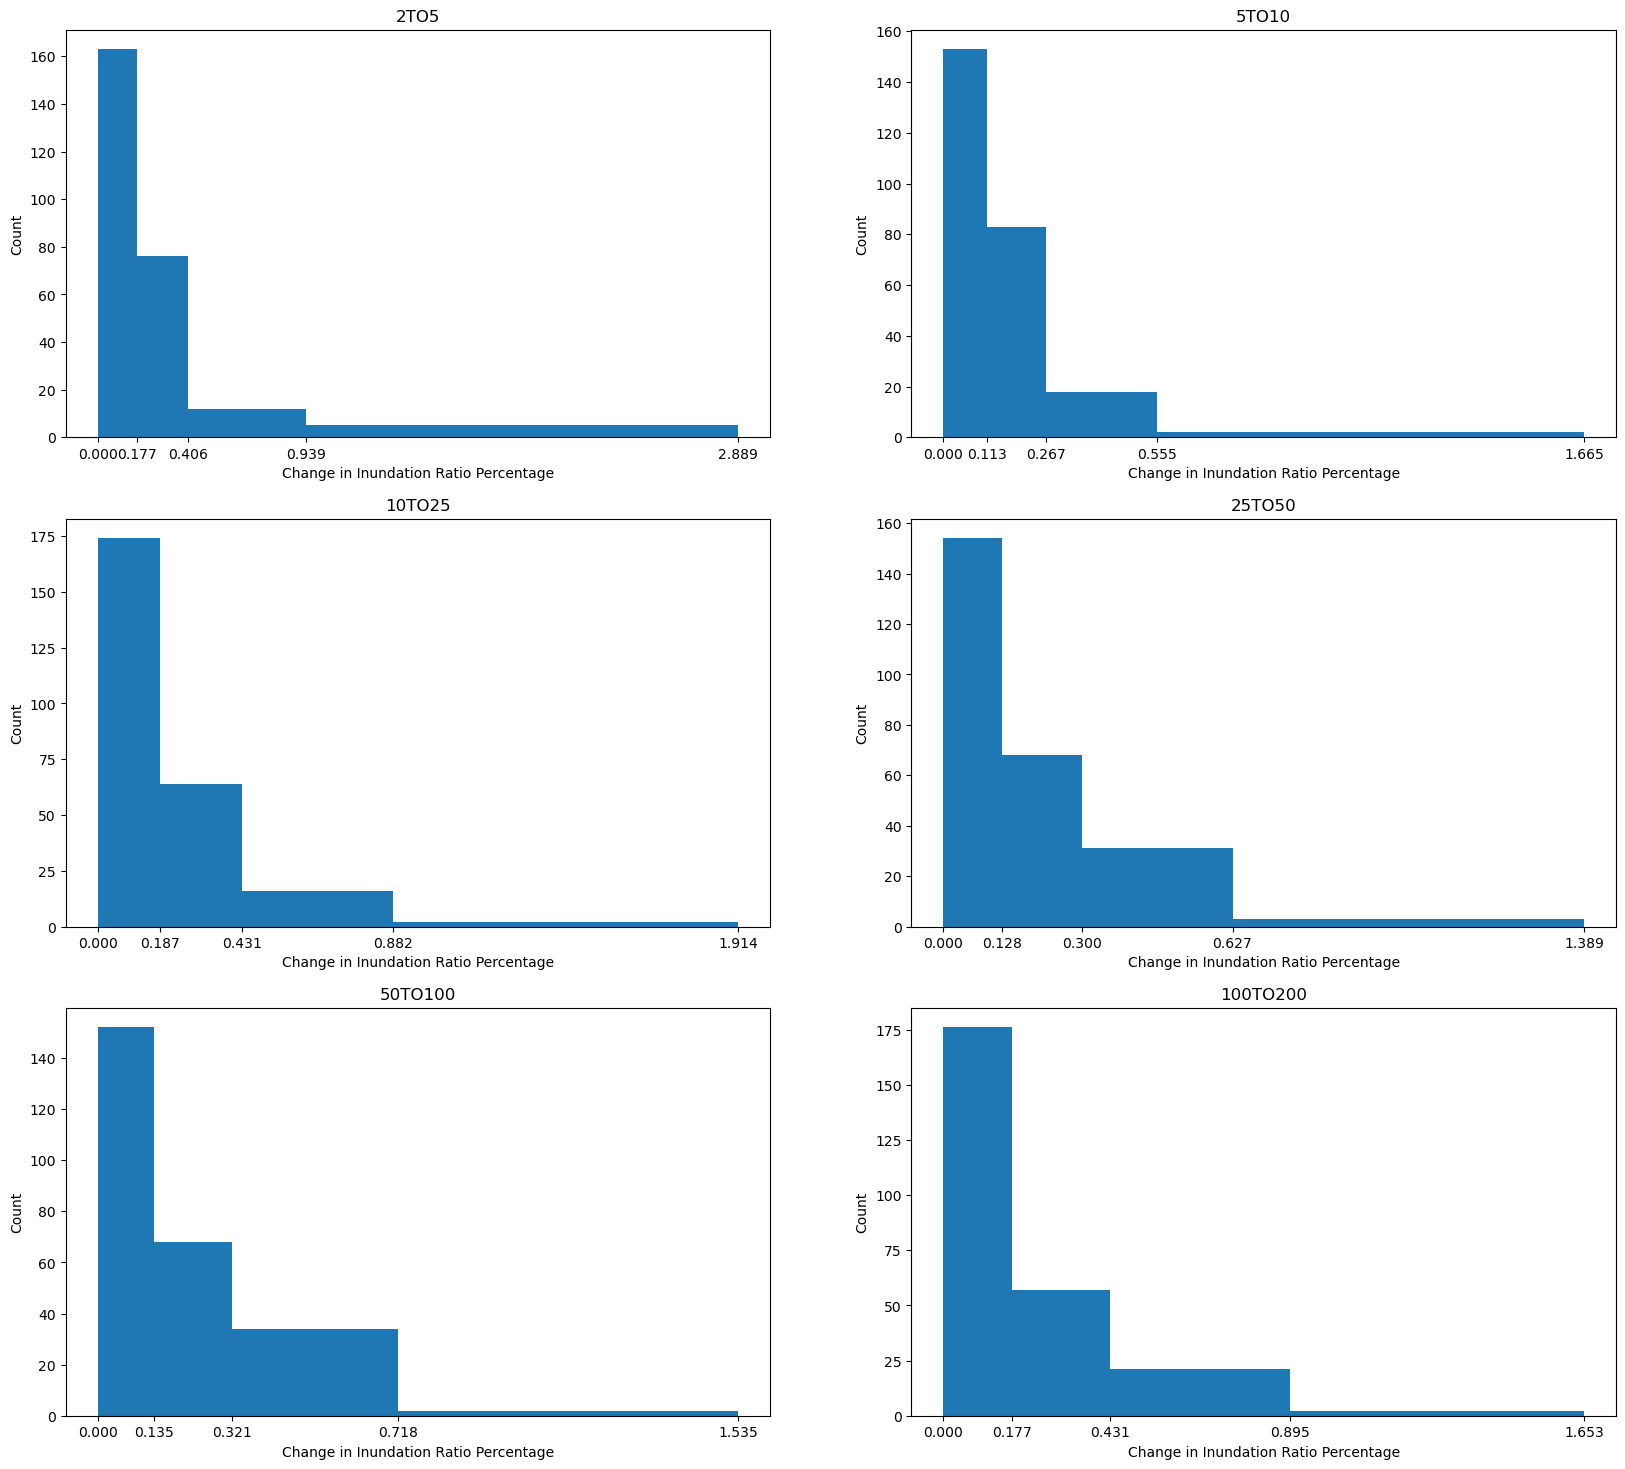

In [38]:
change_plot('/mnt/CADES_CEPH/netzero/inunmap/outputs/stats/site_inun_ratio_PVC_All_256Sites_GeomFixed_epsg5070.csv')

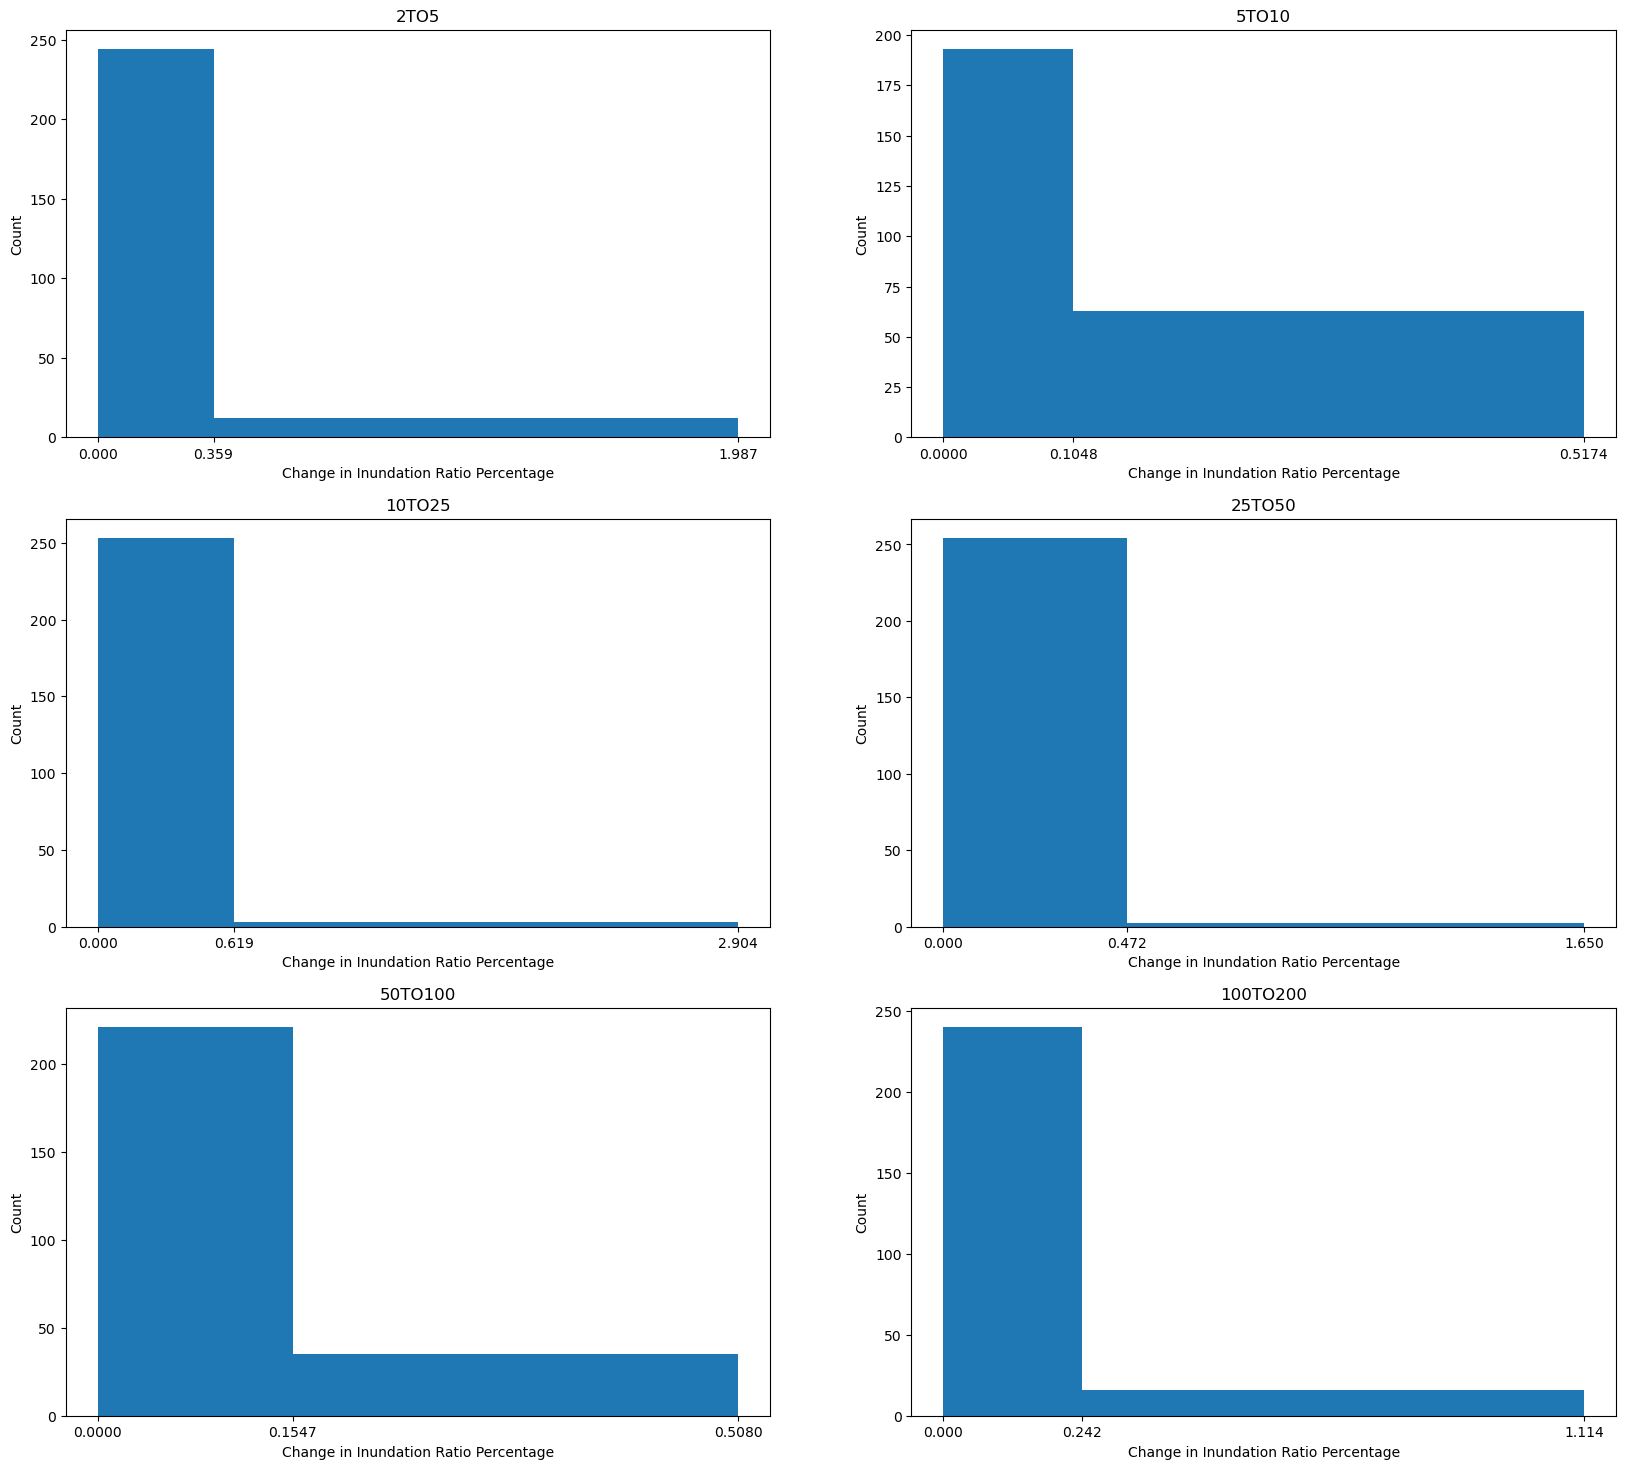

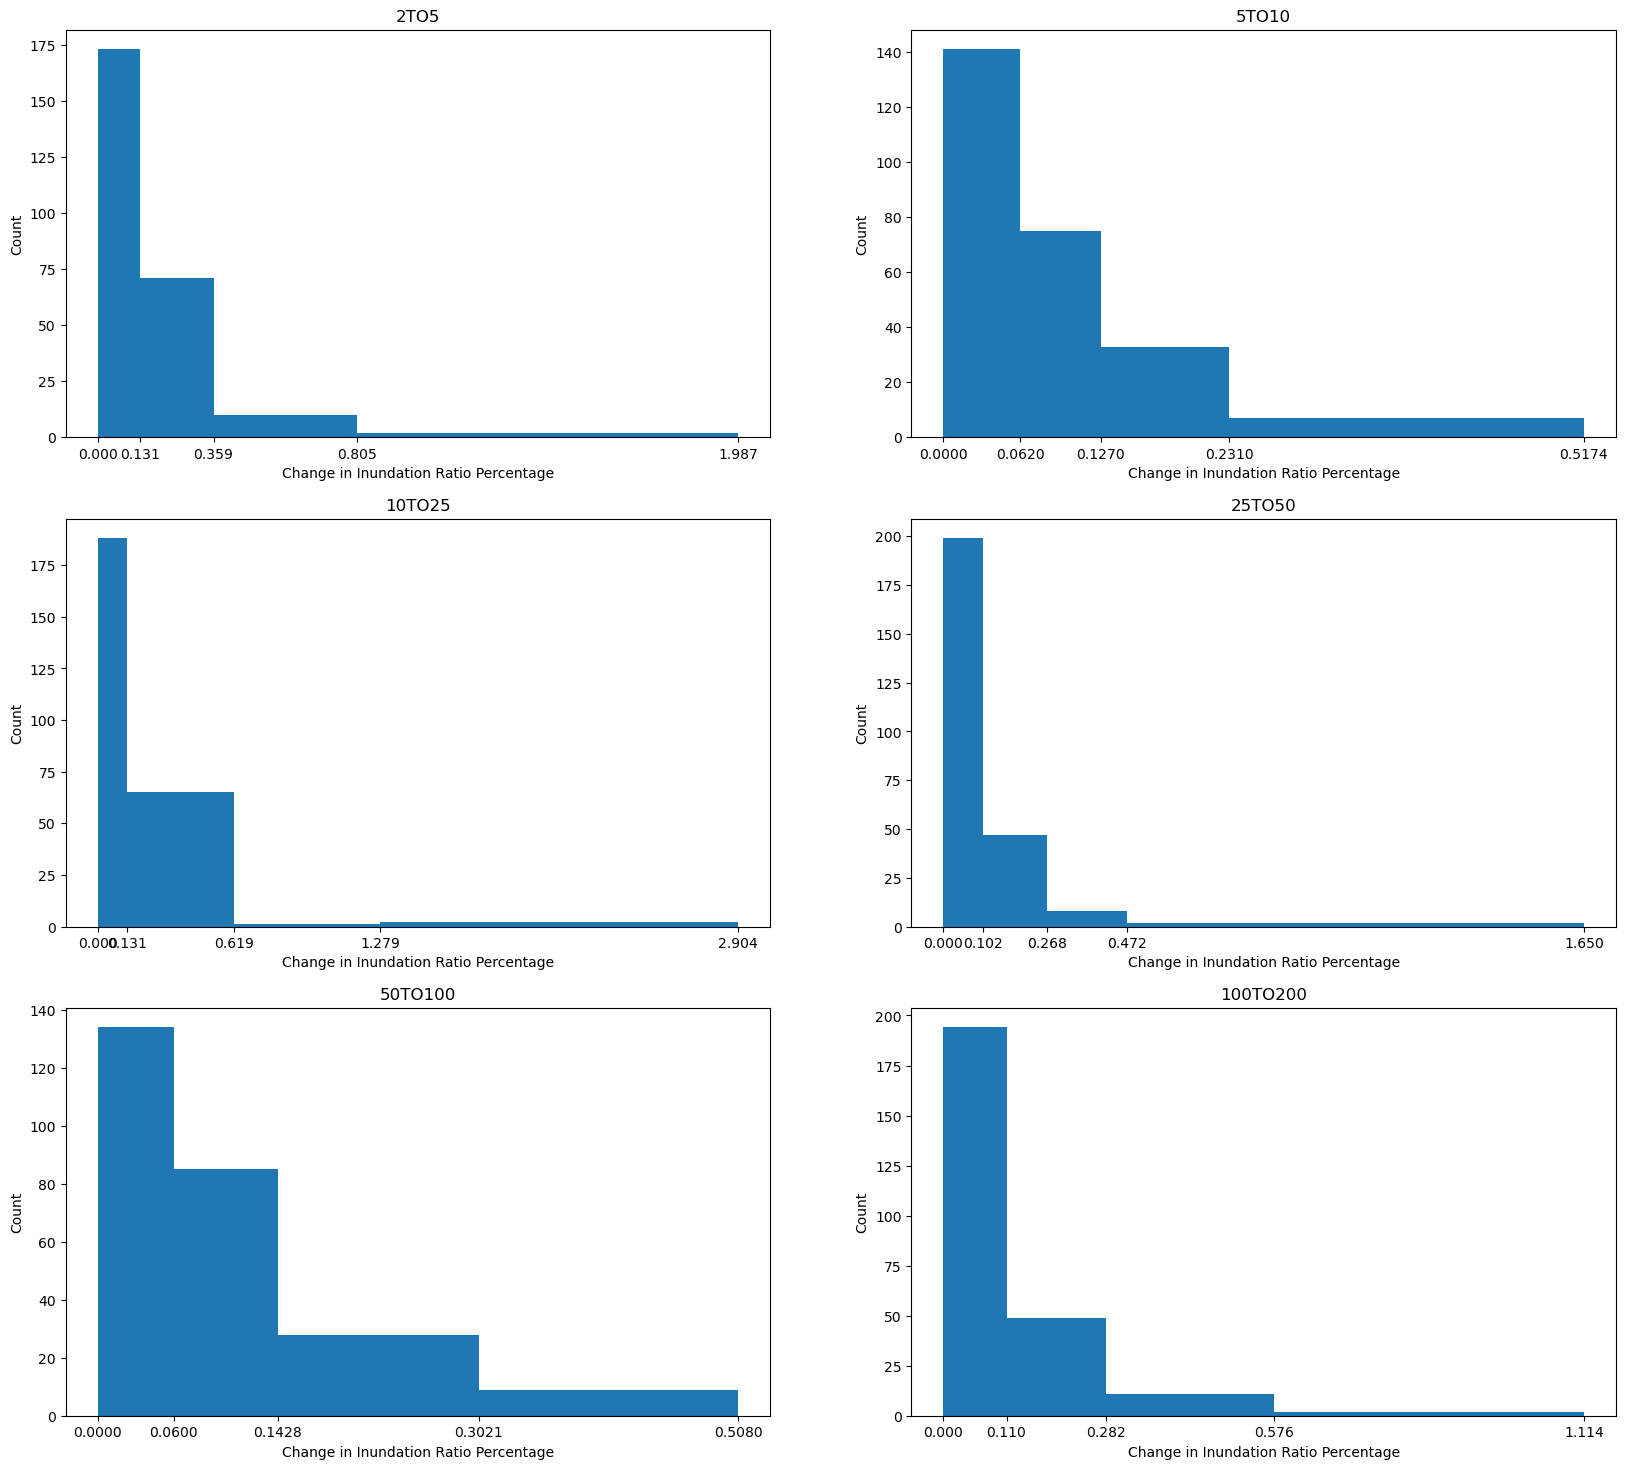

In [45]:
change_plot('/mnt/CADES_CEPH/netzero/inunmap/outputs.GEV_VIC5_RAPID_ACCESS-CM2_ssp585_DBCCA_Daymet_1980_2019_lmom/stats/site_inun_ratio_PVC_All_256Sites_GeomFixed_epsg5070.csv')

In [11]:
csv = '/mnt/CADES_CEPH/netzero/inunmap/outputs/stats/site_inun_ratio_PV_14GW_Sites_GeomFixed_epsg5070.csv'
df = pd.read_csv(csv)
df.head()

,ClusterLab,AREA,RP2,RP5,RP10,RP20,RP25,RP50,RP100,RP200
0,91,9.054796e+06,0.002999,0.003818,0.004111,0.004452,0.004518,0.004733,0.004907,0.005060
1,456,9.082843e+06,0.002746,0.003427,0.003862,0.004211,0.004351,0.004643,0.004884,0.005075
2,489,1.180855e+07,0.002739,0.003319,0.003599,0.003860,0.003960,0.004244,0.004471,0.004683
3,506,1.180863e+07,0.008967,0.010268,0.011147,0.011956,0.012263,0.013036,0.013762,0.014485
4,512,8.176514e+06,0.001232,0.001548,0.001738,0.001932,0.001988,0.002138,0.002272,0.002377


In [7]:
projections = ['GEV_VIC5_RAPID_ACCESS-CM2_ssp585_DBCCA_Daymet_1980_2019_lmom', 'GEV_VIC5_RAPID_ACCESS-CM2_ssp585_DBCCA_Daymet_2020_2059_lmom']
dfs = {}
for projection in projections:
    df = pd.read_csv('/mnt/CADES_CEPH/netzero/inunmap/outputs.' + projection + '/stats/site_inun_area_' + energy_type + '_epsg5070.csv', dtype={'HUC8': str})
    dfs[projection] = df

In [8]:
rps = ['RP2', 'RP5', 'RP10', 'RP20', 'RP25', 'RP50', 'RP100', 'RP200']
x = np.arange(len(rps)) # the bar locations
width = 0.35 # the width of the bars
offsets = [ width * i for i in range(len(projections)) ]

In [16]:
rps = [2, 5, 10, 25, 50, 100, 200]
col_rps = [ f'RP{rp}' for rp in rps ]
col_changes = [ f'{rps[i]}TO{rps[i+1]}' for i in range(len(rps) - 1) ]

Text(0.5, 1.0, 'Total Inundation Area (km^2) on Sites by Return Period (RP) in years')

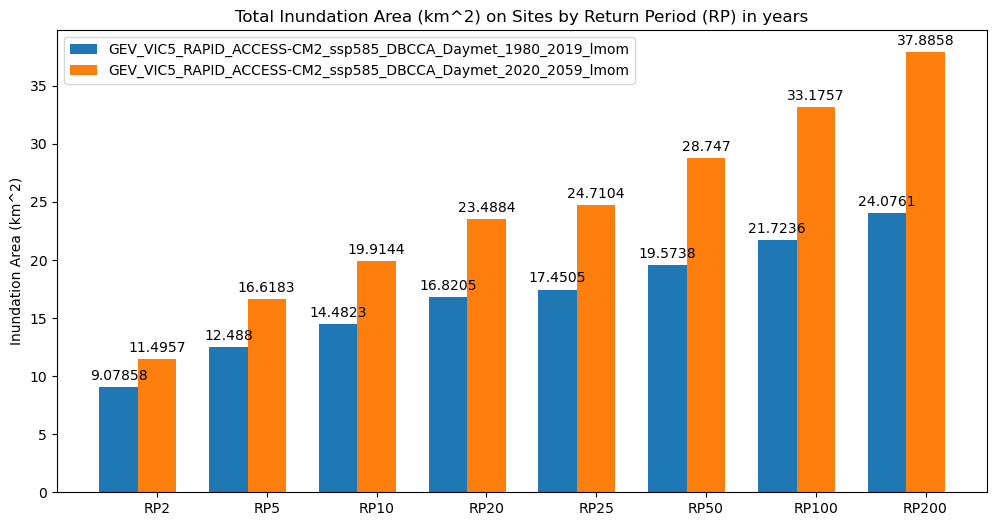

In [10]:
fig, ax = plt.subplots(figsize=(12, 6))
for i, projection in enumerate(projections):
    column_sums = dfs[projection][rps].sum() / 1000000.0 # convert to km^2
    rects = ax.bar(x + offsets[i] , column_sums, width, label=projection)
    ax.bar_label(rects, padding=3)
ax.set_ylabel('Inundation Area (km^2)')
ax.set_xticks(x + width, rps)
ax.legend()
ax.set_title('Total Inundation Area (km^2) on Sites by Return Period (RP) in years')

In [38]:
df_changes = df[col_rps].diff(axis=1)
df_changes.drop(columns=[col_rps[0]], inplace=True)
df_changes['ClusterLab'] = df['ClusterLab']
df_changes.rename(columns={col_rps[i+1]: col_changes[i] for i in range(len(rps) - 1)}, inplace=True)
df_changes = df_changes[['ClusterLab'] + col_changes]
df_changes.head()

,ClusterLab,2TO5,5TO10,10TO25,25TO50,50TO100,100TO200
0,91,0.000819,0.000294,0.000407,0.000215,0.000174,0.000152
1,456,0.000682,0.000435,0.000489,0.000292,0.000240,0.000191
2,489,0.000580,0.000281,0.000360,0.000284,0.000227,0.000212
3,506,0.001301,0.000879,0.001116,0.000773,0.000726,0.000723
4,512,0.000316,0.000191,0.000250,0.000150,0.000134,0.000105


In [40]:
import jenkspy

NameError: name 'col_changes' is not defined

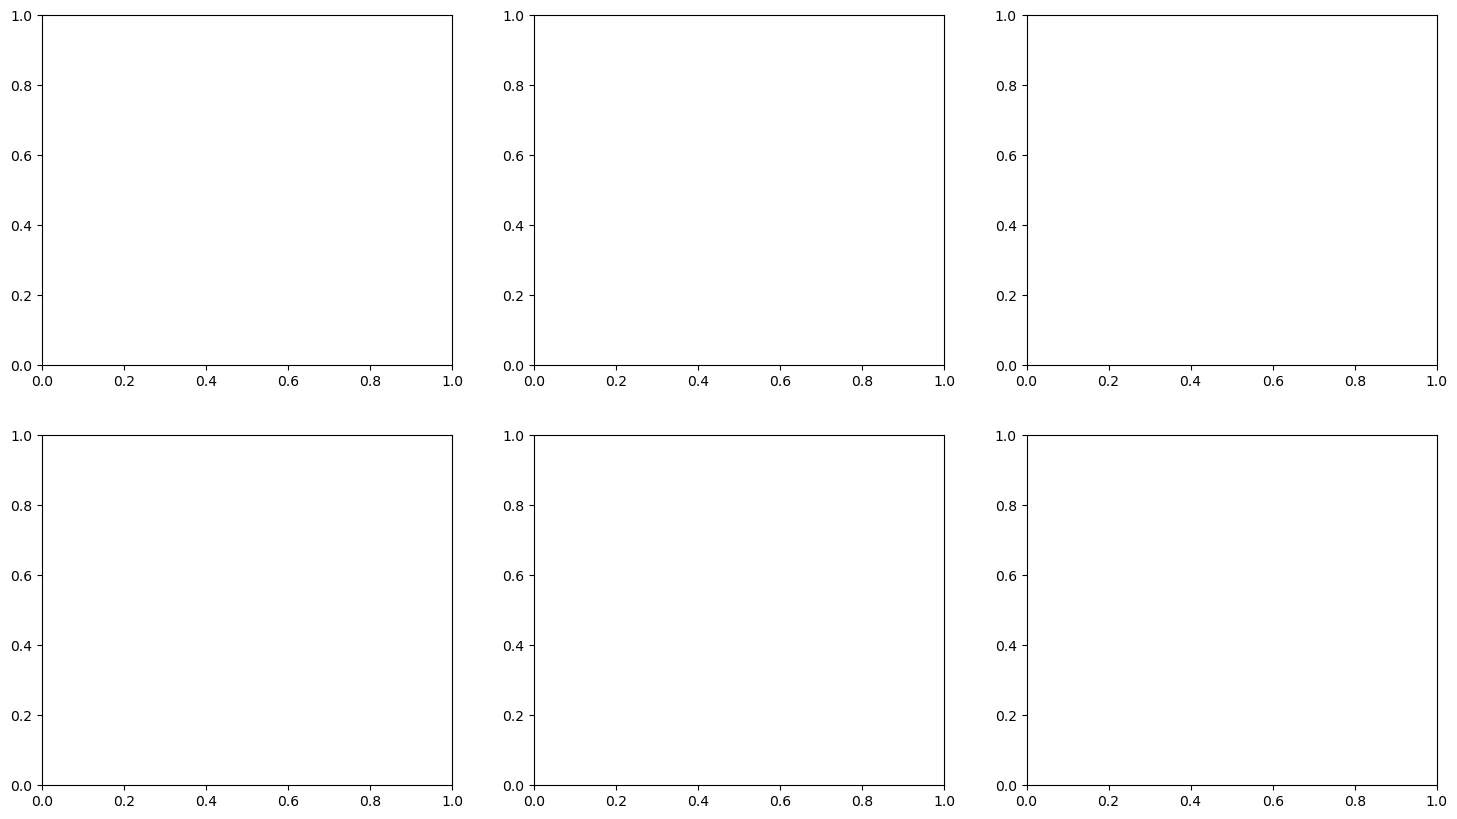

In [ ]:
fig, axs = plt.subplots(2, 3, figsize=(15, 10))
for i, col in enumerate(col_changes):
    data = df_changes[col] * 100
    breaks = jenkspy.jenks_breaks(data, 2)
    axs[i//3, i%3].hist(data, bins=breaks)
    axs[i//3, i%3].set_title(col)
    axs[i//3, i%3].set_xticks(breaks)
    axs[i//3, i%3].set_xlabel('Change in Inundation Ratio Percentage')
    axs[i//3, i%3].set_ylabel('Count')


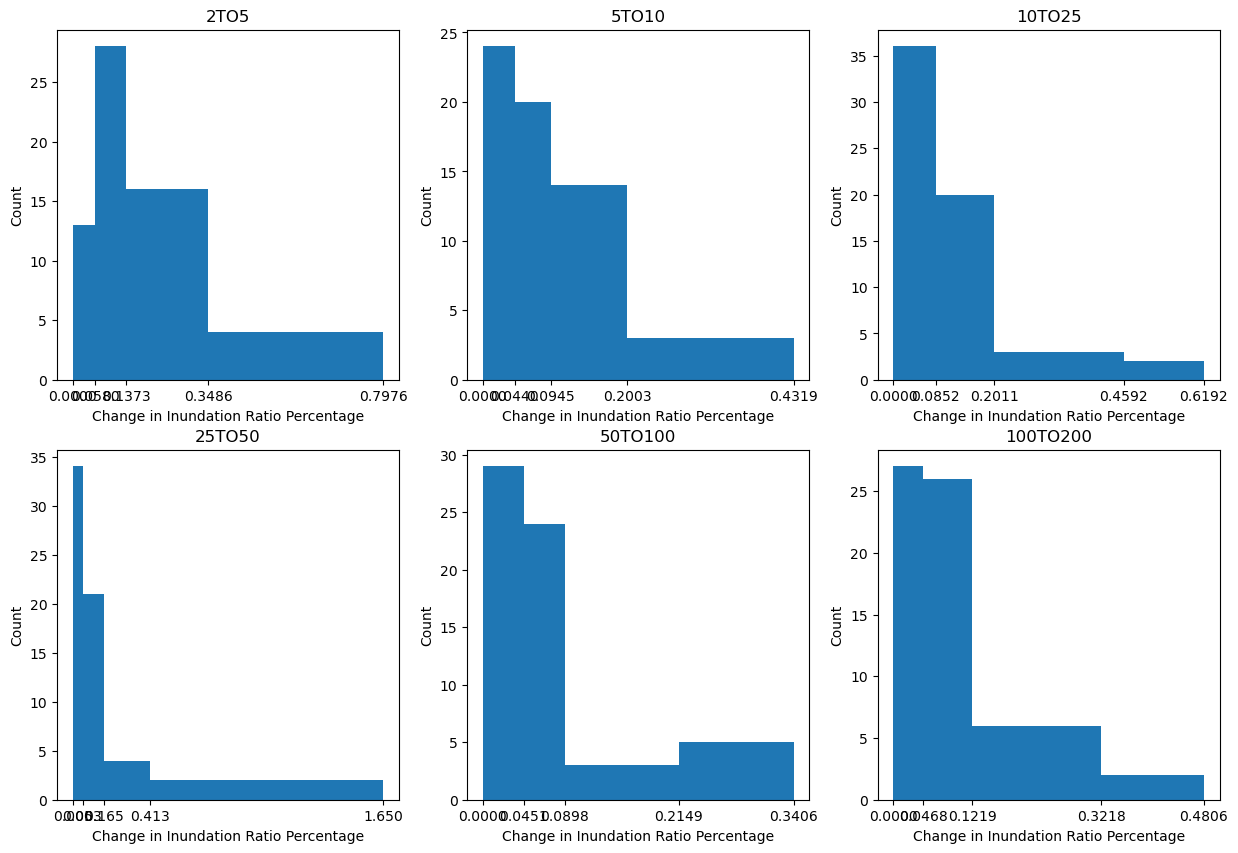

In [51]:
fig, axs = plt.subplots(2, 3, figsize=(15, 10))
for i, col in enumerate(col_changes):
    data = df_changes[col] * 100
    breaks = jenkspy.jenks_breaks(data, 4)
    axs[i//3, i%3].hist(data, bins=breaks)
    axs[i//3, i%3].set_title(col)
    axs[i//3, i%3].set_xticks(breaks)
    axs[i//3, i%3].set_xlabel('Change in Inundation Ratio Percentage')
    axs[i//3, i%3].set_ylabel('Count')


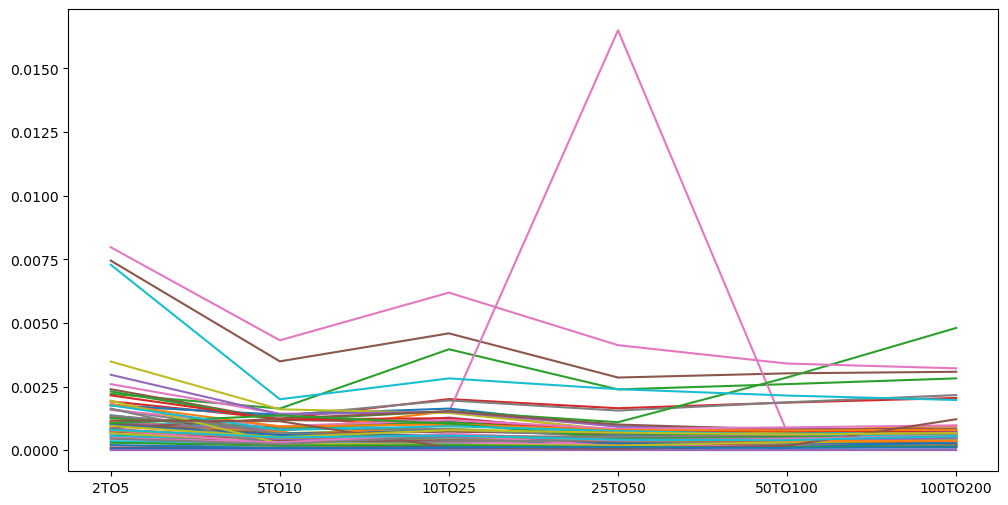

In [39]:
fig, ax = plt.subplots(figsize=(12, 6))
for i in range(len(df_changes)):
    row = df_changes.iloc[i]
    ax.plot(col_changes, row[1:], label=int(row['ClusterLab']))
# ax.set_ylim(0, 1)
#ax.legend()


# compare results before/after invalid site shapes are fixed


In [19]:
csvs = [
    '/mnt/CADES_CEPH/netzero/inunmap/outputs/stats/site_inun_ratio_PV_14GW_Sites_GeomFixed_epsg5070.csv',
    '/mnt/CADES_CEPH/netzero/inunmap/outputs/stats/stats1/site_inun_ratio_PVC_14GW_Footprints_Dec20_epsg5070.csv'
    ]
dfs = [ pd.read_csv(csv) for csv in csvs ]
rps = [2, 5, 10, 25, 50, 100, 200]
col_rps = [ f'RP{rp}' for rp in rps ]
dfs = [ df[col_rps] for df in dfs ]
diff = dfs[0] - dfs[1]
diff.describe()

,RP2,RP5,RP10,RP25,RP50,RP100,RP200
count,6.100000e+01,6.100000e+01,6.100000e+01,6.100000e+01,6.100000e+01,6.100000e+01,6.100000e+01
mean,-4.233944e-06,1.205972e-05,9.987067e-06,9.886983e-06,9.857147e-06,9.547950e-06,6.933882e-06
std,3.849360e-05,8.738635e-05,7.048300e-05,6.859138e-05,6.762817e-05,6.456393e-05,4.378728e-05
min,-2.991813e-04,-2.305208e-06,-2.665217e-06,-3.947846e-06,-6.431226e-06,-6.574520e-06,-6.746561e-06
25%,-3.146139e-07,-4.223335e-07,-4.266653e-07,-4.479358e-07,-3.914033e-07,-4.745643e-07,-5.095283e-07
50%,0.000000e+00,0.000000e+00,8.446033e-08,2.658843e-07,3.740728e-07,3.619966e-07,3.161262e-07
75%,7.923851e-07,1.163538e-06,1.360500e-06,1.861514e-06,2.325682e-06,2.608535e-06,3.162968e-06
max,1.950970e-05,6.828813e-04,5.507742e-04,5.360401e-04,5.284785e-04,5.045206e-04,3.416798e-04


In [20]:
csvs = [
    '/mnt/CADES_CEPH/netzero/inunmap/outputs/stats/site_inun_ratio_PVC_All_256Sites_GeomFixed_epsg5070.csv',
    '/mnt/CADES_CEPH/netzero/inunmap/outputs/stats/stats1/site_inun_ratio_PVC_All_Potential_Sites_epsg5070.csv'
    ]
dfs = [ pd.read_csv(csv) for csv in csvs ]
rps = [2, 5, 10, 25, 50, 100, 200]
col_rps = [ f'RP{rp}' for rp in rps ]
dfs = [ df[col_rps] for df in dfs ]
diff = dfs[0] - dfs[1]
diff.describe()

,RP2,RP5,RP10,RP25,RP50,RP100,RP200
count,2.560000e+02,2.560000e+02,2.560000e+02,2.560000e+02,2.560000e+02,2.560000e+02,2.560000e+02
mean,1.091639e-07,5.303313e-06,5.683595e-06,6.147883e-06,6.920223e-06,8.241743e-06,9.039537e-06
std,2.488150e-05,5.748038e-05,6.294806e-05,6.935680e-05,8.151334e-05,1.023464e-04,1.224719e-04
min,-2.991812e-04,-9.357046e-05,-1.131802e-04,-1.422029e-04,-1.768441e-04,-2.050589e-04,-2.256799e-04
25%,-2.701423e-07,-4.009856e-07,-4.079166e-07,-4.386969e-07,-4.439054e-07,-4.737203e-07,-5.177864e-07
50%,3.581536e-09,2.166350e-08,7.103501e-08,2.361362e-07,2.353797e-07,2.672406e-07,3.350929e-07
75%,7.104959e-07,1.033084e-06,1.166566e-06,1.401340e-06,1.618683e-06,2.266574e-06,2.162524e-06
max,2.526988e-04,6.828814e-04,8.369592e-04,9.625521e-04,1.180432e-03,1.545617e-03,1.916962e-03


# compute flood extent stats
Run this after running `netzero/inunmap/bin/flood_extent_stats.py`. 

We compare the data b/w the past and the future projections.

In [39]:
projections = ['GEV_VIC5_RAPID_ACCESS-CM2_ssp585_DBCCA_Daymet_1980_2019_lmom', 'GEV_VIC5_RAPID_ACCESS-CM2_ssp585_DBCCA_Daymet_2020_2059_lmom']
dfs = {}
for projection in projections:
    df = pd.read_csv('/mnt/CADES_CEPH/netzero/inunmap/outputs.' + projection + '/stats/fp_stats.csv', dtype={'HUC8': str})
    dfs[projection] = df

In [40]:
dfs[projections[0]].head()

,HUC8,RP2,RP5,RP10,RP20,RP25,RP50,RP100,RP200
0,03150101,89.573616,102.926619,111.296070,119.473965,122.092587,130.131144,138.149226,146.529936
1,03150102,57.614274,65.317590,69.731298,74.058858,75.324744,79.072731,82.636092,86.364225
2,03150103,69.318684,80.733771,88.239609,95.465070,97.474158,103.804164,110.229570,116.319699
3,03150105,211.729356,243.004410,263.034414,283.311306,289.006146,309.501369,331.759863,350.122374
4,03150106,289.004445,320.954427,339.531732,353.657547,358.344036,370.318923,380.968173,391.009059


In [41]:
dfs[projections[1]].head()

,HUC8,RP2,RP5,RP10,RP20,RP25,RP50,RP100,RP200
0,03150101,95.147217,108.857952,117.125442,124.656462,126.970515,134.225721,141.254370,148.289292
1,03150102,62.381583,71.830053,77.876766,83.135295,84.755421,90.188316,94.826034,99.605457
2,03150103,75.296151,88.676208,97.468290,105.107400,107.759772,115.171830,122.794290,130.057101
3,03150105,226.078488,266.366268,289.082376,313.276185,320.190606,340.907076,366.593121,389.024784
4,03150106,305.129979,346.273101,371.172168,394.086888,400.975326,422.001090,442.600524,463.019967


In [42]:
rps = ['RP2', 'RP5', 'RP10', 'RP20', 'RP25', 'RP50', 'RP100', 'RP200']
x = np.arange(len(rps)) # the bar locations
width = 0.35 # the width of the bars
offsets = [ width * i for i in range(len(projections)) ]

Text(0.5, 1.0, 'Total Inundation Are (sqkm) by Return Period (RP) in years')

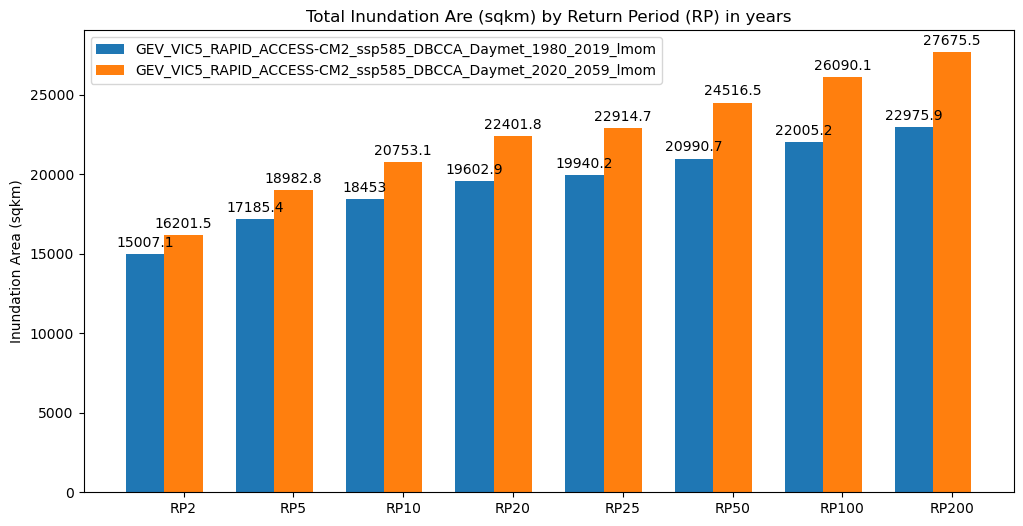

In [43]:
fig, ax = plt.subplots(figsize=(12, 6))
for i, projection in enumerate(projections):
    column_sums = dfs[projection][rps].sum()
    rects = ax.bar(x + offsets[i] , column_sums, width, label=projection)
    ax.bar_label(rects, padding=3)
ax.set_ylabel('Inundation Area (sqkm)')
ax.set_xticks(x + width, rps)
ax.legend()
ax.set_title('Total Inundation Are (sqkm) by Return Period (RP) in years')

Text(0.5, 1.0, 'Total Inundation Are (sqkm) by Return Period (RP) in years\n HUC8 06040002')

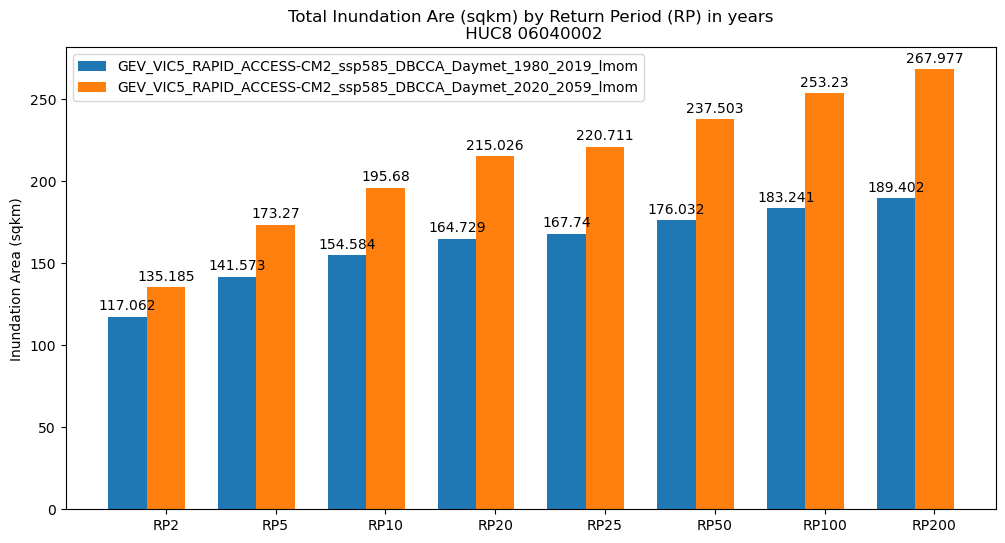

In [44]:
fig, ax = plt.subplots(figsize=(12, 6))
for i, projection in enumerate(projections):
    df = dfs[projection]
    df_06040002 = df[df['HUC8'] == '06040002']
    column_sums = df_06040002[rps].sum()
    rects = ax.bar(x + offsets[i] , column_sums, width, label=projection)
    ax.bar_label(rects, padding=3)
ax.set_ylabel('Inundation Area (sqkm)')
ax.set_xticks(x + width, rps)
ax.legend()
ax.set_title('Total Inundation Are (sqkm) by Return Period (RP) in years\n HUC8 06040002')

In [31]:
df_06040002 = df[df['HUC8'] == '06040002']
df_06040002.head()

,HUC8,RP2,RP5,RP10,RP20,RP25,RP50,RP100,RP200
63,06040002,135.185427,173.270385,195.679683,215.026191,220.711293,237.502755,253.229544,267.976818


<Axes: title={'center': 'Inundation area (sqkm) by return period (FP) in years\n HUC8 06040002'}>

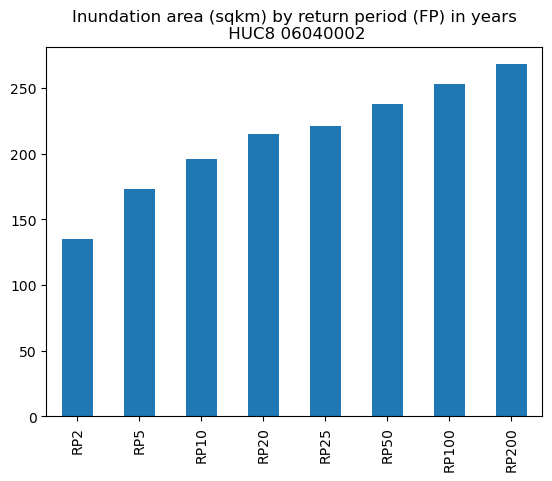

In [ ]:
df_06040002[rps].sum().plot(kind='bar', title='Inundation area (sqkm) by return period (FP) in years\n HUC8 06040002')

<Axes: >

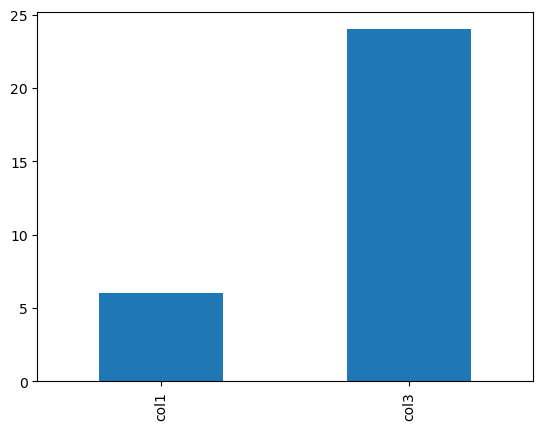

In [3]:
df = pd.DataFrame({'col1': [1, 2, 3], 'col2': [4, 5, 6], 'col3': [7, 8, 9]})
df = df[['col1', 'col3']]
column_sums = df.sum()
column_sums.plot(kind='bar')

# scatter plot: x - LCOE, y - RP, color - district

Create scatterplot CSV:

```bash
# all solar sites
cd /mnt/CADES_CEPH/netzero/inunmap/outputs.GEV_VIC5_RAPID_ACCESS-CM2_ssp585_DBCCA_Daymet_1980_2019_lmom/stats
# join attributes
ogr2ogr -dialect OGRSQL -sql "select all_sites.*, cast(s.ClusterLab as integer) as ClusterLab2, cast(s.AREA as float) as AREA2, cast(s.RP2 as float) as RP2,  cast(s.RP5 as float) as RP5,  cast(s.RP10 as float) as RP10,  cast(s.RP20 as float) as RP20,  cast(s.RP25 as float) as RP25,  cast(s.RP50 as float) as RP50,  cast(s.RP100 as float) as RP100, cast(s.RP200 as float) as RP200 from all_sites left join 'site_inun_ratio_PVC_All_256Sites_GeomFixed_epsg5070.csv'.site_inun_ratio_PVC_All_256Sites_GeomFixed_epsg5070 as s on all_sites.ClusterLab = s.ClusterLab" site_inun_ratio_PVC_All_256Sites_GeomFixed_epsg5070.gpkg ../../inputs/PVC_All_256Sites_GeomFixed_epsg5070.gpkg -nln all_sites
# convert to csv
cd /mnt/CADES_CEPH/netzero/inunmap
ogr2ogr -dialect sqlite -sql "select * from all_sites" outputs.GEV_VIC5_RAPID_ACCESS-CM2_ssp585_DBCCA_Daymet_2020_2059_lmom/stats/site_inun_ratio_PVC_All_256Sites_GeomFixed_epsg5070_scatterplot.csv outputs.GEV_VIC5_RAPID_ACCESS-CM2_ssp585_DBCCA_Daymet_2020_2059_lmom/stats/site_inun_ratio_PVC_All_256Sites_GeomFixed_epsg5070.gpkg

# some solar sites - no longer needed
ogr2ogr -dialect OGRSQL -sql "select siteshape.*, cast(s.ClusterLab as integer) as ClusterLab2, cast(s.AREA as float) as AREA2, cast(s.RP2 as float) as RP2,  cast(s.RP5 as float) as RP5,  cast(s.RP10 as float) as RP10,  cast(s.RP20 as float) as RP20,  cast(s.RP25 as float) as RP25,  cast(s.RP50 as float) as RP50,  cast(s.RP100 as float) as RP100, cast(s.RP200 as float) as RP200 from siteshape left join 'site_inun_ratio_PV_14GW_Sites_GeomFixed_epsg5070.csv'.site_inun_ratio_PV_14GW_Sites_GeomFixed_epsg5070 as s on siteshape.ClusterLab = s.ClusterLab" site_inun_ratio_PV_14GW_Sites_GeomFixed_epsg5070.gpkg ../../inputs/PV_14GW_Sites_GeomFixed_epsg5070.gpkg -nln siteshape
```

In [2]:
projections = ['GEV_VIC5_RAPID_ACCESS-CM2_ssp585_DBCCA_Daymet_1980_2019_lmom', 'GEV_VIC5_RAPID_ACCESS-CM2_ssp585_DBCCA_Daymet_2020_2059_lmom']
projection_titles = ['Historical Projection (1980-2019)', 'Future Projection (2020-2059)']
csvs = ['/mnt/CADES_CEPH/netzero/inunmap/outputs.' + projection + '/stats/site_inun_ratio_PVC_All_256Sites_GeomFixed_epsg5070_scatterplot.csv' for projection in projections]
rps = ['RP2', 'RP5', 'RP10', 'RP20', 'RP25', 'RP50', 'RP100', 'RP200']
dfs = [ pd.read_csv(csv, usecols=['ClusterLab2', 'all_sites.MEAN_LCOE_', 'all_sites.FIRST_DI_1'] + rps) for csv in csvs ]

In [3]:
ddfs = []
for df in dfs:
    df.rename(columns={'all_sites.MEAN_LCOE_': 'LCOE', 'all_sites.FIRST_DI_1': 'District'}, inplace=True)
    ddfs.append(df.groupby('District'))

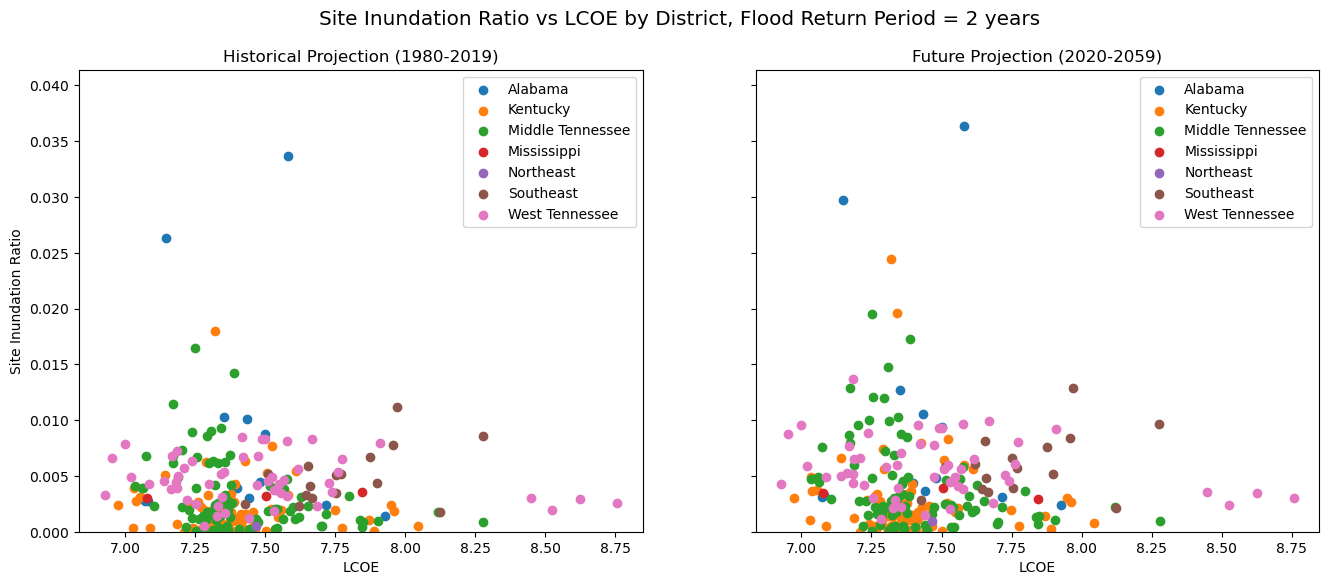

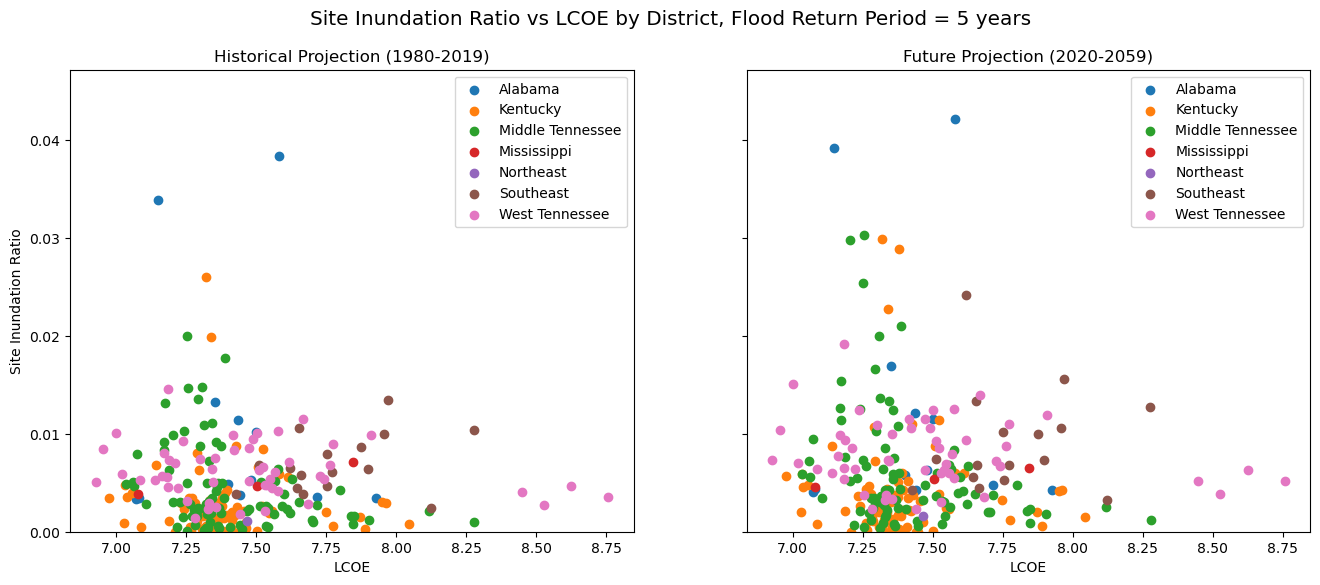

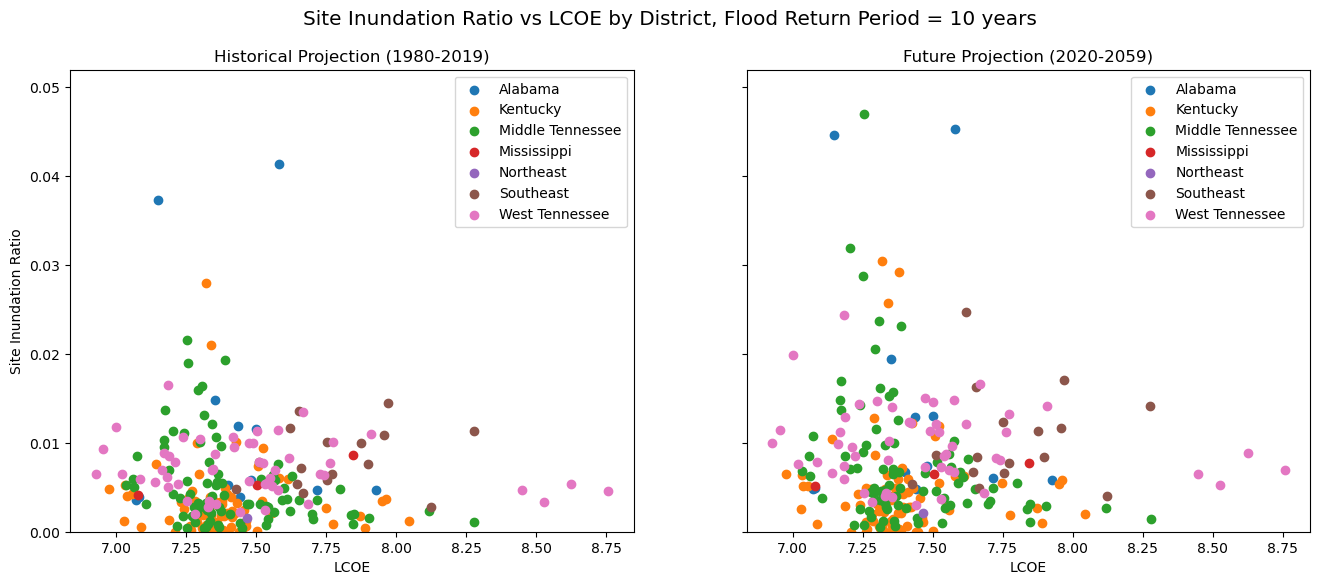

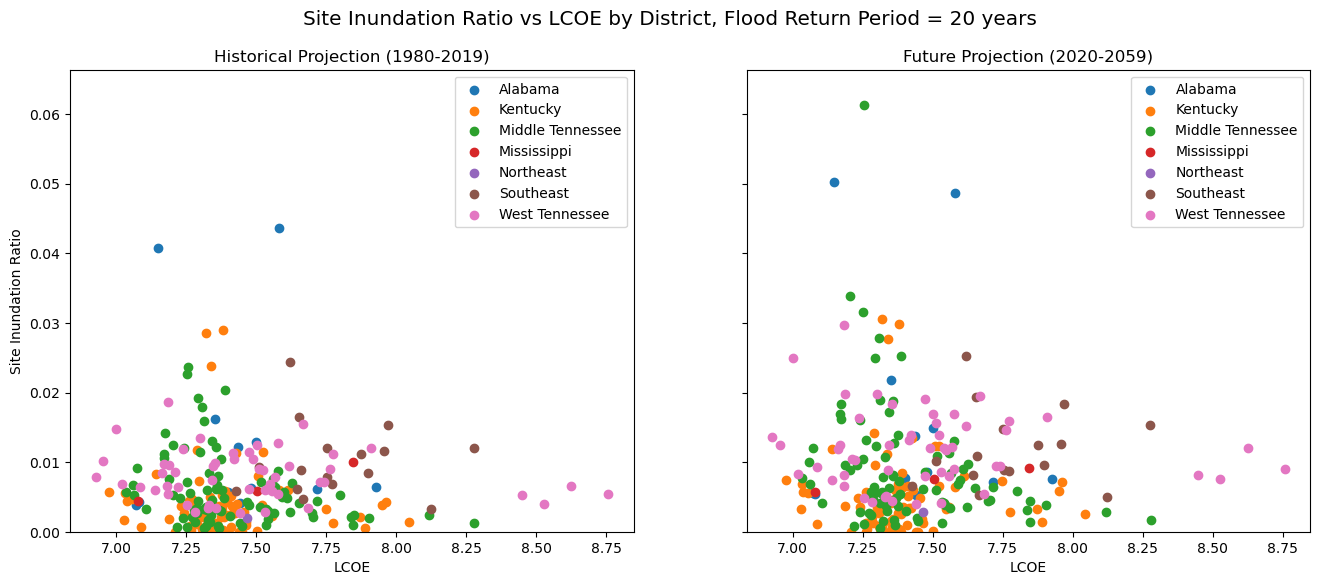

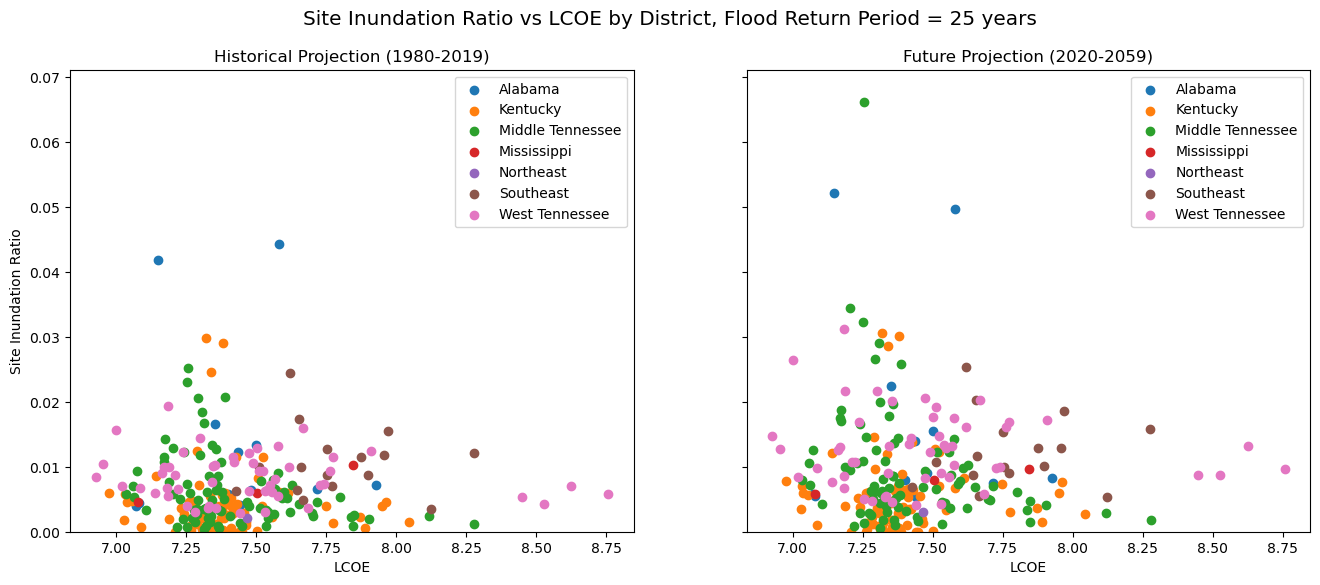

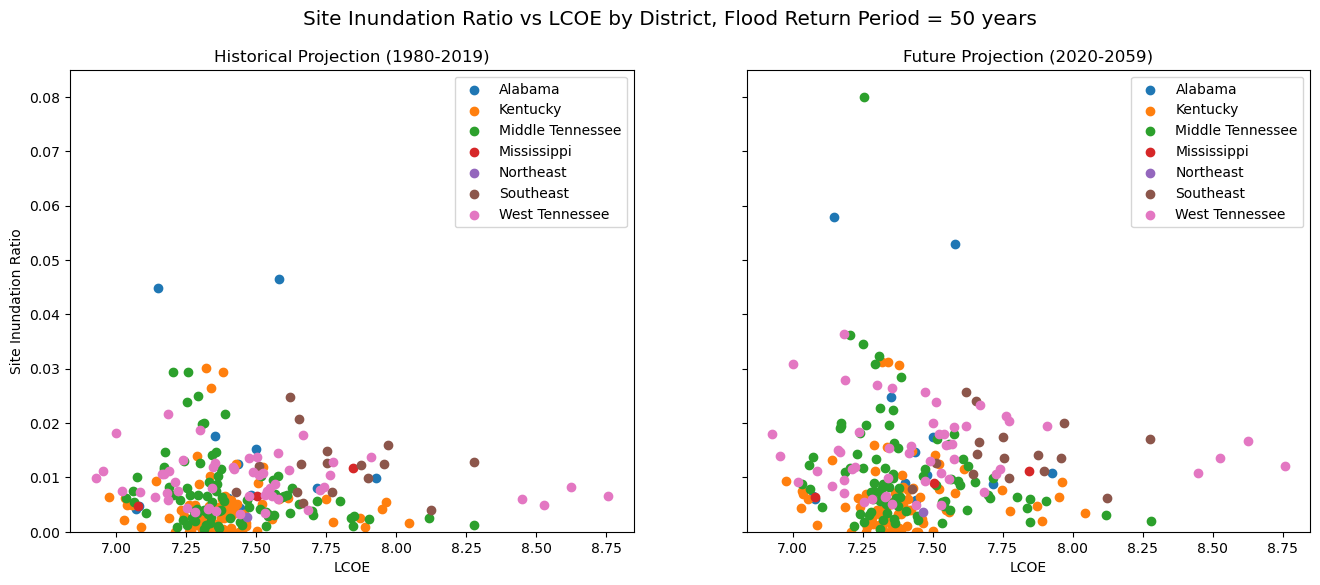

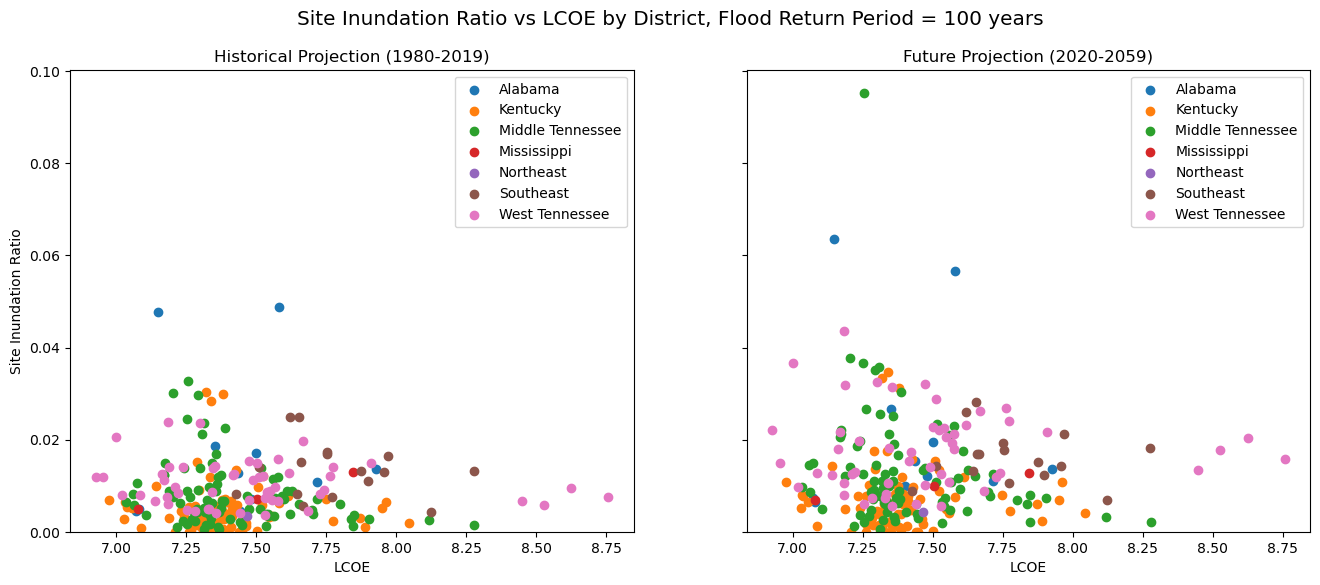

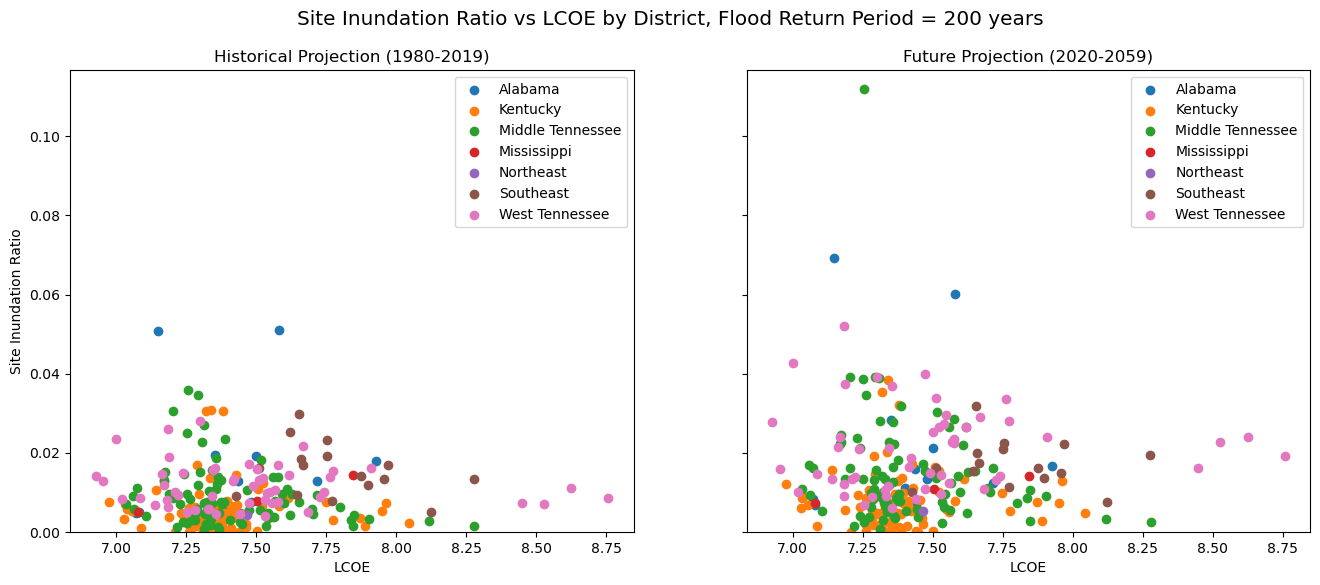

In [4]:
for rp in rps:
    # create two scatter plots for each projection
    fig, axs = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
    rp_max = max([df[rp].max() for df in dfs])
    for i, projection in enumerate(projections):
        for district, group in ddfs[i]:
            # plot scatter plot: x = LCOE, y = RP, label = district
            axs[i].scatter(group['LCOE'], group[rp], label=district)
        axs[i].set_title(projection_titles[i])
        axs[i].set_xlabel('LCOE')
        if i == 0:
            axs[i].set_ylabel('Site Inundation Ratio')
        else:
            axs[i].set_ylabel('')
        axs[i].set_ylim(0, rp_max + 0.005)
        axs[i].legend()
    #handles, labels = axs[0].get_legend_handles_labels()
    #fig.legend(handles, labels, loc='center', bbox_to_anchor=(0.535, 0.7), fontsize='large', framealpha=0.6) #loc='center right', fontsize='large')
    fig.suptitle('Site Inundation Ratio vs LCOE by District, Flood Return Period = ' + rp.split('RP')[1] + ' years', fontsize='x-large')
    plt.show()

In [6]:
dfs[1].head()

,District,LCOE,ClusterLab2,RP2,RP5,RP10,RP20,RP25,RP50,RP100,RP200
0,Mississippi,7.845649,22,0.002925,0.006473,0.007707,0.009199,0.009692,0.011153,0.012701,0.014209
1,Mississippi,7.078368,91,0.003494,0.004513,0.005089,0.005659,0.005818,0.006354,0.006832,0.007342
2,Mississippi,7.503668,98,0.003881,0.005420,0.006478,0.007540,0.007957,0.009018,0.009997,0.010808
3,Alabama,7.500236,150,0.009389,0.011552,0.013040,0.014882,0.015558,0.017364,0.019424,0.021176
4,Alabama,7.440713,198,0.003640,0.004264,0.004751,0.005248,0.005391,0.005745,0.006056,0.006415


ValueError: 'c' argument must be a color, a sequence of colors, or a sequence of numbers, not array(['Mississippi', 'Mississippi', 'Mississippi', 'Alabama', 'Alabama',
       'Alabama', 'Alabama', 'Alabama', 'Southeast', 'Southeast',
       'Alabama', 'Alabama', 'Alabama', 'Alabama', 'West Tennessee',
       'Alabama', 'West Tennessee', 'Middle Tennessee', 'West Tennessee',
       'Middle Tennessee', 'Alabama', 'Alabama', 'Middle Tennessee',
       'West Tennessee', 'Middle Tennessee', 'Southeast',
       'Middle Tennessee', 'Middle Tennessee', 'Southeast',
       'Middle Tennessee', 'Middle Tennessee', 'Middle Tennessee',
       'West Tennessee', 'West Tennessee', 'Middle Tennessee',
       'Middle Tennessee', 'West Tennessee', 'West Tennessee',
       'West Tennessee', 'Middle Tennessee', 'West Tennessee',
       'West Tennessee', 'Middle Tennessee', 'Middle Tennessee',
       'West Tennessee', 'West Tennessee', 'West Tennessee',
       'Middle Tennessee', 'West Tennessee', 'Middle T

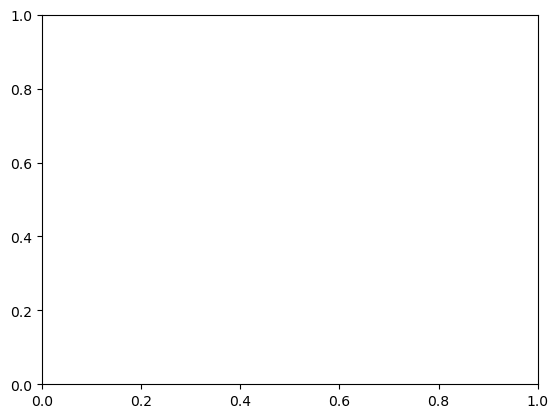

In [8]:
dfs[0].plot.scatter(x='LCOE', c='District', y='RP2', colormap='viridis')

# shapely geometry intersect tests

In [19]:
import shapely
import shapely.geometry
import matplotlib.pyplot as plt
import pandas as pd

0.25


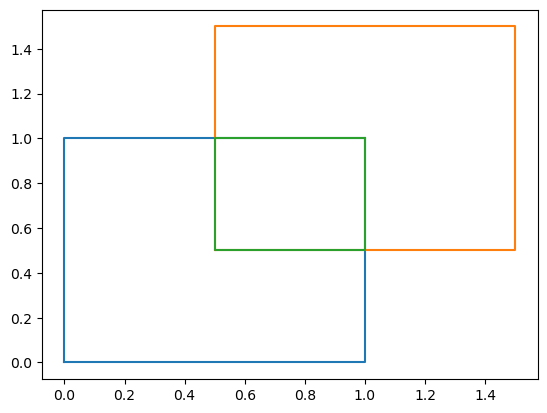

In [6]:
p1 = shapely.geometry.Polygon([(0, 0), (1, 0), (1, 1), (0, 1)])
p2 = shapely.geometry.Polygon([(0.5, 0.5), (1.5, 0.5), (1.5, 1.5), (0.5, 1.5)])
pi = p1.intersection(p2)
print(pi.area)

fig, ax = plt.subplots()
for polygon in [p1, p2, pi]:
    x, y = polygon.exterior.xy
    ax.plot(x, y)


In [7]:
p1.geom_type

'Polygon'

0.0 Polygon


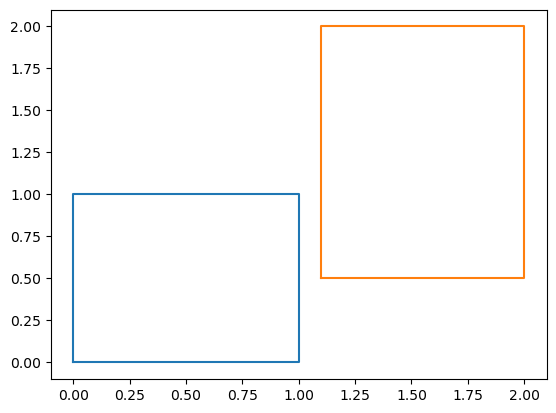

In [14]:
p1 = shapely.geometry.Polygon([(0, 0), (1, 0), (1, 1), (0, 1)])
p2 = shapely.geometry.Polygon([(1.1, 0.5), (2, 0.5), (2, 2), (1.1, 2)])
pi = p1.intersection(p2)
print(pi.area, pi.geom_type)

fig, ax = plt.subplots()
for polygon in [p1, p2, pi]:
    x, y = polygon.exterior.xy
    ax.plot(x, y)


In [15]:
pi.exterior.xy

(array('d'), array('d'))

0.0 LineString


AttributeError: 'LineString' object has no attribute 'exterior'

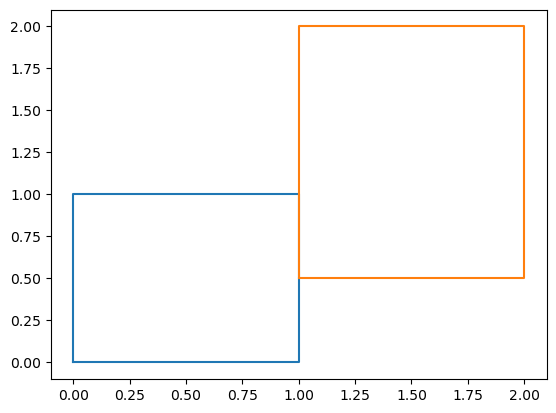

In [16]:
p1 = shapely.geometry.Polygon([(0, 0), (1, 0), (1, 1), (0, 1)])
p2 = shapely.geometry.Polygon([(1, 0.5), (2, 0.5), (2, 2), (1, 2)])
pi = p1.intersection(p2)
print(pi.area, pi.geom_type)

fig, ax = plt.subplots()
for polygon in [p1, p2, pi]:
    x, y = polygon.exterior.xy
    ax.plot(x, y)


0.0 Point


AttributeError: 'Point' object has no attribute 'exterior'

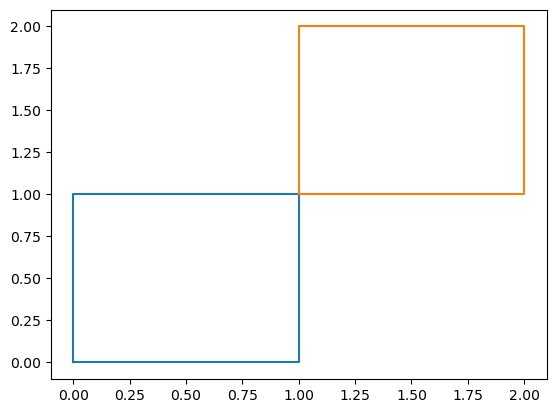

In [17]:
p1 = shapely.geometry.Polygon([(0, 0), (1, 0), (1, 1), (0, 1)])
p2 = shapely.geometry.Polygon([(1, 1), (2, 1), (2, 2), (1, 2)])
pi = p1.intersection(p2)
print(pi.area, pi.geom_type)

fig, ax = plt.subplots()
for polygon in [p1, p2, pi]:
    x, y = polygon.exterior.xy
    ax.plot(x, y)


In [26]:
rps = ['RP2', 'RP5', 'RP10', 'RP20', 'RP25', 'RP50', 'RP100', 'RP200']
inun_ratio = pd.read_csv('/mnt/CADES_CEPH/netzero/inunmap/outputs/stats/site_inun_ratio_PVC_14GW_Footprints_Dec20_epsg5070.csv')
inun_ratio[rps].max()

RP2      0.026361
RP5      0.033811
RP10     0.037304
RP20     0.040777
RP25     0.041897
RP50     0.044754
RP100    0.047775
RP200    0.050859
dtype: float64

In [27]:
inun_ratio = pd.read_csv('/mnt/CADES_CEPH/netzero/inunmap/outputs/stats/site_inun_ratio_PVC_All_Potential_Sites.csv')
inun_ratio[rps].max()

RP2      0.033645
RP5      0.038334
RP10     0.041374
RP20     0.043580
RP25     0.044292
RP50     0.046513
RP100    0.048785
RP200    0.051014
dtype: float64

<Axes: >

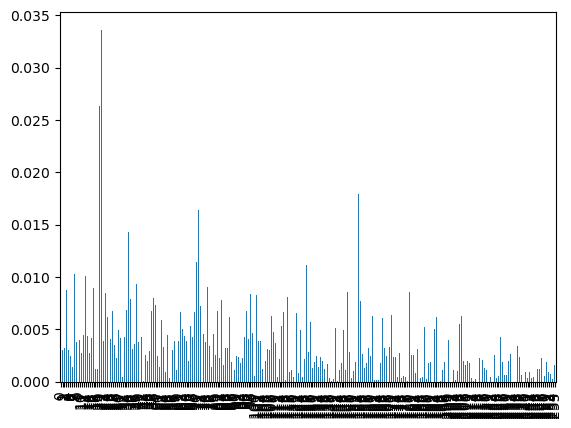

In [29]:
inun_ratio[rps[0]].plot(kind='bar')

# Performance debug: `process_braided_w_max()`
This function `process_braided_w_max()` is too slow, taking 80% of the inunmap time.

- Jupyter kernel: `inunmap`

In [1]:
import numpy as np
import numpy.ma as ma
import pickle
import matplotlib.pyplot as plt

import os, sys, time, subprocess
import pandas as pd
import shapely
import shapely.geometry
import shapely.errors
import shapely.ops
import fiona
import fiona.crs
import rasterio
import rasterio.mask
import rasterio.features
import rasterio.windows
import affine
import json

import rtree
import math
import random

import csv
from collections import OrderedDict

In [2]:
rdir = '/mnt/CADES_CEPH/netzero/inunmap'
handdir = '/mnt/CADES_CEPH/pin2flood/prod'
odir = rdir + '/' + 'outputs'
tdir = '/mnt/CADES_CEPH/pin2flood/cache/inunmap' #'/dev/shm/climate/tmp'
waterdepth_app = '//mnt/CADES_CEPH/fim3/taudem/TauDEM-waterdepth/bin/waterdepth'
if not os.path.isdir(odir+'/extent_grid') or not os.path.isdir(odir+'/extent_vector') or not os.path.isdir(odir+'/depth_grid'):
    print('ERROR, output dir', odir, '/{extent_grid|extent_vector|depth_grid}', 'does not exist')
    exit(1)
f_braided_lookup = '/mnt/CADES_CEPH/fim3/cahaba/ornl/braided_streams/braided_streams_lookup_minor2main.pickle'

huc = '03170001'

f_hhand = handdir +'/' + huc + '/' + 'rem_zeroed_masked_healed.tif'

f_catchgrid = handdir +'/' + huc + '/' + 'gw_catchments_reaches_filtered_addedAttributes.tif'

f_hydrotable = handdir +'/' + huc + '/' + 'hydroTable.csv'

fcfile = '/mnt/CADES_CEPH/netzero/inunmap/inputs/GEV_VIC5_RAPID_ACCESS-CM2_ssp585_DBCCA_Daymet_1980_2019_lmom.csv' # sys.argv[2]
period = 'Daymet_1980_2019' # sys.argv[3]
rps=['FP50', 'FP100', 'FP200']
print("===InunMap for HUC", huc, " for period", period, flush=True)
print("scenarios:", rps)
sys.stdout.flush()

===InunMap for HUC 03170001  for period Daymet_1980_2019
scenarios: ['FP50', 'FP100', 'FP200']


In [3]:
d_hydrotable = pd.read_csv(f_hydrotable, usecols=['HydroID', 'feature_id', 'stage', 'discharge_cms'])
d_hydrotable.rename(columns={'feature_id': 'COMID'}, inplace = True)
comids_h = np.unique(d_hydrotable['COMID'].to_numpy())
print('num of unique COMIDs in hydrotable:', comids_h.size)

num of unique COMIDs in hydrotable: 1399


In [6]:
d_ffreq = pd.read_csv(fcfile, usecols=['COMID']+rps)
comids_f = np.unique(d_ffreq['COMID'])


num of unique COMIDs in forecast file: 2677612


In [9]:
print('num of unique COMIDs in forecast file:', comids_f.size, ', total:', len(d_ffreq))

num of unique COMIDs in forecast file: 2677612 , total: 2677612


In [7]:
with open(f_braided_lookup, 'rb') as f:
    lookup = pickle.load(f)

In [8]:
print('num of braided streams lookup table:', len(lookup))

num of braided streams lookup table: 66128


In [28]:
def process_braided_w_max(comids_h, f_braided_lookup_dict, d_ffreq, rps):
    with open(f_braided_lookup_dict, 'rb') as f:
        lookup = pickle.load(f) # dict: minor --> main
    # build HUC lookup: 1 - see if any comid is a main stream
    comids_h_set = set(comids_h)
    main2minors_list = [ (v, k) for k, v in lookup.items() if v in comids_h_set ]
    main2minors = {}
    for main, minor in main2minors_list:
        if not main in main2minors:
            main2minors[main] = [minor]
        else:
            main2minors[main].append(minor)
    # build HUC lookup: 2 - see if any comid is a minor stream
    for comid in comids_h:
        if comid in lookup:
            main = lookup[comid]
            if not main in main2minors:
                main2minors[main] = [comid]
            else:
                main2minors[main].append(minor) # possible a minor is added in both step 1 and 2
    # reformat lookup to a list of [all comids of a braided area]
    # regardless comid is minor or main
    braided_list = [ [k] + v for k,v in main2minors.items() ]
    # for each braided area, replace streamflow columns with max
    count = 0
    rowcount = 0
    for braided in braided_list:
        # Note: we assume all main/minor COMIDs have forecast data. Otherwise, behavior not defined.
        fc_data = d_ffreq.loc[d_ffreq['COMID'].isin(braided), rps]
        fc_data.fillna(0, inplace=True)
        num_rows = fc_data.shape[0]
        if num_rows <= 0:
            continue
        col_max  = fc_data.max()
        new_coldata =  [ [col_max[col]] * num_rows for col in rps ]
        new_coldata = np.array(new_coldata, dtype=np.float64).transpose()
        d_ffreq.loc[d_ffreq['COMID'].isin(braided), rps] = new_coldata # do not use pd.DataFrame(newdata...)
        count += 1
        rowcount += num_rows
    print('process_braided_w_max():', count, 'braided areas,', rowcount, 'rows are replaced with max')

In [29]:
process_braided_w_max(comids_h, f_braided_lookup, d_ffreq, rps)

process_braided_w_max(): 2 braided areas, 5 rows are replaced with max


In [18]:
braided = braided_list[0]
fc_data = d_ffreq.loc[d_ffreq['COMID'].isin(braided), rps]
fc_data.fillna(0, inplace=True)
fc_data

,FP50,FP100,FP200
393115,0.0000,0.0000,0.0000
397660,1.0016,1.1990,1.4216
416281,29.9515,36.3592,43.7639


In [21]:
col_max = fc_data.max()

In [23]:
new_coldata =  [ [col_max[col]] * fc_data.shape[0] for col in rps ]
new_coldata

[[np.float64(29.9515), np.float64(29.9515), np.float64(29.9515)],
 [np.float64(36.3592), np.float64(36.3592), np.float64(36.3592)],
 [np.float64(43.7639), np.float64(43.7639), np.float64(43.7639)]]

In [24]:
new_coldata = np.array(new_coldata, dtype=np.float64).transpose()

In [25]:
new_coldata

array([[29.9515, 36.3592, 43.7639],
       [29.9515, 36.3592, 43.7639],
       [29.9515, 36.3592, 43.7639]])

In [27]:
d_ffreq.loc[d_ffreq['COMID'].isin(braided), rps] = new_coldata

# remove small polygons: test area size

In [30]:
import fiona
import shapely
import shapely.geometry

In [31]:
f = fiona.open('/mnt/CADES_CEPH/netzero/inunmap/outputs/extent_vector/extent_03170001_period_Daymet_1980_2019_scenario_FP200.gpkg')

In [35]:
c = 0
for feature in f:
    geom = shapely.geometry.shape(feature['geometry'])
    if geom.area <= 36.0:
        c += 1
print(c)

100136


# Missing data handling of Ganesh's flood freq data

In [14]:
import pandas as pd
import numpy as np
import fiona

In [16]:
tva_comids = []
with fiona.open('/mnt/CADES_CEPH/fim3/data/nwm_hydrofab_flowlines_within_tva_temp.gpkg', layer='flowline') as src:
    for f in src:
        tva_comids.append(f['properties']['ID'])
print('Number of TVA COMIDs:', len(tva_comids))

Number of TVA COMIDs: 184467


In [9]:
df = pd.read_csv('/mnt/CADES_CEPH/netzero/inunmap/inputs/GEV_VIC5_RAPID_ACCESS-CM2_ssp585_DBCCA_Daymet_1980_2019_lmom.csv', usecols=['COMID', 'FP50', 'FP100', 'FP200'])

In [17]:
tva_comids = set(tva_comids)
df = df[df['COMID'].isin(tva_comids)]

In [11]:
df.dtypes

COMID      int64
FP50     float64
FP100    float64
FP200    float64
dtype: object

In [19]:
len(df[df['FP50'] < 0.01])

453

<AxesSubplot:>

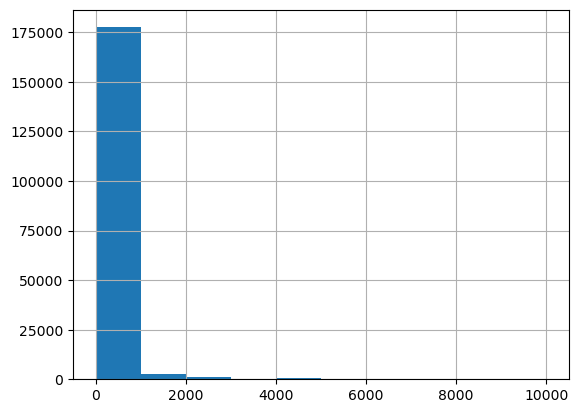

In [30]:
df['FP200'].clip(lower=0, upper=10000).hist(bins=10)